In [1]:
# Import Google Drive from Google Colab
from google.colab import drive

drive.mount('/content/drive/',force_remount=True)

Mounted at /content/drive/


In [2]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
 import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU available!")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU not available. Using CPU.")

print("Device:", device)

GPU available!
GPU: Tesla T4
Device: cuda


In [4]:
import os

DATASET_PATH = "/content/drive/MyDrive/miniproject"
FILE_NAME = "03-01-2018.csv"

FILE_PATH = os.path.join(
    DATASET_PATH,
    FILE_NAME
)

print("Dataset path:")
print(FILE_PATH)

print("\nFile exists:", os.path.exists(FILE_PATH))

Dataset path:
/content/drive/MyDrive/miniproject/03-01-2018.csv

File exists: True


In [5]:
# Check files in the project folder

print("Files inside miniproject folder:")

for file in os.listdir(DATASET_PATH):
    print(file)

Files inside miniproject folder:
02-14-2018.csv
02-15-2018.csv
02-16-2018.csv
02-20-2018.csv
02-21-2018.csv
02-22-2018.csv
02-23-2018.csv
02-28-2018.csv
03-01-2018.csv
03-02-2018.csv


In [6]:
# Load CSE-CIC-IDS2018 dataset

df = pd.read_csv(
    FILE_PATH,
    nrows=500000
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

/tmp/ipykernel_1116/3030198219.py:3: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Dataset loaded successfully!
Dataset shape: (331125, 80)


In [7]:
# ============================================================
# LOAD CSE-CIC-IDS2018 DATA
# ============================================================

csv_files = [
    "02-14-2018.csv",
    "02-15-2018.csv",
    "02-16-2018.csv",
    "02-20-2018.csv",
    "02-21-2018.csv",
    "02-22-2018.csv",
    "02-23-2018.csv",
    "02-28-2018.csv",
    "03-01-2018.csv",
    "03-02-2018.csv"
]

dataframes = []

# Number of rows to take from each file
ROWS_PER_FILE = 50000

for file_name in csv_files:

    file_path = os.path.join(
        DATASET_PATH,
        file_name
    )

    print(f"Loading: {file_name}")

    temp_df = pd.read_csv(
        file_path,
        nrows=ROWS_PER_FILE
    )

    print(
        f"  Shape: {temp_df.shape}"
    )

    dataframes.append(temp_df)

# Combine all files
df = pd.concat(
    dataframes,
    ignore_index=True
)

print("\n================================")
print("All files loaded!")
print("Final dataset shape:", df.shape)
print("================================")

Loading: 02-14-2018.csv
  Shape: (50000, 80)
Loading: 02-15-2018.csv
  Shape: (50000, 80)
Loading: 02-16-2018.csv
  Shape: (50000, 80)
Loading: 02-20-2018.csv
  Shape: (50000, 84)
Loading: 02-21-2018.csv
  Shape: (50000, 80)
Loading: 02-22-2018.csv
  Shape: (50000, 80)
Loading: 02-23-2018.csv
  Shape: (50000, 80)
Loading: 02-28-2018.csv


/tmp/ipykernel_1116/3367943576.py:32: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  temp_df = pd.read_csv(


  Shape: (50000, 80)
Loading: 03-01-2018.csv


/tmp/ipykernel_1116/3367943576.py:32: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  temp_df = pd.read_csv(


  Shape: (50000, 80)
Loading: 03-02-2018.csv
  Shape: (50000, 80)

All files loaded!
Final dataset shape: (500000, 84)


In [8]:
print("Number of columns:", len(df.columns))

print("\nColumns:")
for i, column in enumerate(df.columns):
    print(i, ":", column)

Number of columns: 84

Columns:
0 : Dst Port
1 : Protocol
2 : Timestamp
3 : Flow Duration
4 : Tot Fwd Pkts
5 : Tot Bwd Pkts
6 : TotLen Fwd Pkts
7 : TotLen Bwd Pkts
8 : Fwd Pkt Len Max
9 : Fwd Pkt Len Min
10 : Fwd Pkt Len Mean
11 : Fwd Pkt Len Std
12 : Bwd Pkt Len Max
13 : Bwd Pkt Len Min
14 : Bwd Pkt Len Mean
15 : Bwd Pkt Len Std
16 : Flow Byts/s
17 : Flow Pkts/s
18 : Flow IAT Mean
19 : Flow IAT Std
20 : Flow IAT Max
21 : Flow IAT Min
22 : Fwd IAT Tot
23 : Fwd IAT Mean
24 : Fwd IAT Std
25 : Fwd IAT Max
26 : Fwd IAT Min
27 : Bwd IAT Tot
28 : Bwd IAT Mean
29 : Bwd IAT Std
30 : Bwd IAT Max
31 : Bwd IAT Min
32 : Fwd PSH Flags
33 : Bwd PSH Flags
34 : Fwd URG Flags
35 : Bwd URG Flags
36 : Fwd Header Len
37 : Bwd Header Len
38 : Fwd Pkts/s
39 : Bwd Pkts/s
40 : Pkt Len Min
41 : Pkt Len Max
42 : Pkt Len Mean
43 : Pkt Len Std
44 : Pkt Len Var
45 : FIN Flag Cnt
46 : SYN Flag Cnt
47 : RST Flag Cnt
48 : PSH Flag Cnt
49 : ACK Flag Cnt
50 : URG Flag Cnt
51 : CWE Flag Count
52 : ECE Flag Cnt
53 : Down

In [9]:
print("Label distribution:")

print(
    df["Label"].value_counts()
)

Label distribution:
Label
Benign                      212756
DDoS attacks-LOIC-HTTP       49927
FTP-BruteForce               49895
DoS attacks-SlowHTTPTest     49881
DDOS attack-HOIC             46067
Bot                          40455
DoS attacks-GoldenEye        38790
DoS attacks-Slowloris         9565
DDOS attack-LOIC-UDP          1730
Brute Force -Web               611
Brute Force -XSS               230
SQL Injection                   87
Label                            6
Name: count, dtype: int64


In [10]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Label column exists:", "Label" in df.columns)
print("Number of columns:", len(df.columns))

Label column exists: True
Number of columns: 84


In [91]:
# Count missing values in each column
missing = df.isnull().sum()

print("Total missing values:", missing.sum())
print("\nColumns with missing values:")
print(missing[missing > 0])

Total missing values: 1481410

Columns with missing values:
Flow Byts/s      1693
Flow Pkts/s      1329
Flow ID        369597
Src IP         369597
Src Port       369597
Dst IP         369597
dtype: int64


In [92]:
print("Missing values in X:", X.isnull().sum().sum())
print("Infinite values in X:", np.isinf(X.select_dtypes(include="number")).sum().sum())

Missing values in X: 373503
Infinite values in X: 0


In [11]:
# Replace infinite values with NaN
df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows where the label is missing
df = df.dropna(subset=["Label"])

print("Dataset shape after cleaning:", df.shape)
print("Missing labels:", df["Label"].isna().sum())

Dataset shape after cleaning: (500000, 84)
Missing labels: 0


In [12]:
# Check duplicates
duplicates = df.duplicated().sum()
print("Duplicate rows:", duplicates)

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 80403
Dataset shape after removing duplicates: (419597, 84)


In [13]:
# Convert labels into binary classes
df["Target"] = df["Label"].apply(
    lambda x: 0 if str(x).strip().upper() == "BENIGN" else 1
)

print("Binary label distribution:")
print(df["Target"].value_counts())

print("\nClass meaning:")
print("0 = Benign")
print("1 = Attack")

Binary label distribution:
Target
0    212671
1    206926
Name: count, dtype: int64

Class meaning:
0 = Benign
1 = Attack


In [14]:
# Separate input features and target
X = df.drop(columns=["Label", "Target"])
y = df["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (419597, 83)
y shape: (419597,)

Target distribution:
Target
0    212671
1    206926
Name: count, dtype: int64


In [15]:
# Convert all feature columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with NaN
X = X.replace([np.inf, -np.inf], np.nan)

print("X shape:", X.shape)
print("Total missing feature values:", X.isna().sum().sum())

X shape: (419597, 83)
Total missing feature values: 2051891


In [16]:
# Find columns that contain only missing values
all_nan_columns = X.columns[X.isna().all()].tolist()

print("Completely empty columns:", len(all_nan_columns))

if len(all_nan_columns) > 0:
    print(all_nan_columns)

# Remove completely empty columns
X = X.dropna(axis=1, how="all")

print("\nX shape after removing empty columns:", X.shape)

Completely empty columns: 4
['Timestamp', 'Flow ID', 'Src IP', 'Dst IP']

X shape after removing empty columns: (419597, 79)


In [17]:
# First: 80% temporary data + 20% test data
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: split the remaining 80% into
# 70% training and 10% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.125,
    random_state=42,
    stratify=y_train_full
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nClass distribution:")
print("Train:")
print(y_train.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nTest:")
print(y_test.value_counts())

Training set: (293717, 79)
Validation set: (41960, 79)
Test set: (83920, 79)

Class distribution:
Train:
Target
0    148869
1    144848
Name: count, dtype: int64

Validation:
Target
0    21267
1    20693
Name: count, dtype: int64

Test:
Target
0    42535
1    41385
Name: count, dtype: int64


In [18]:
# Calculate medians using ONLY the training set
train_medians = X_train.median()

# Fill missing values in all three sets
X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing values after imputation:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

Missing values after imputation:
Train: 0
Validation: 0
Test: 0


In [19]:
# Find features with zero variance in the training set
constant_columns = X_train.columns[X_train.nunique() <= 1].tolist()

print("Constant features:", len(constant_columns))

if len(constant_columns) > 0:
    print(constant_columns)

# Remove the same columns from all datasets
X_train = X_train.drop(columns=constant_columns)
X_val = X_val.drop(columns=constant_columns)
X_test = X_test.drop(columns=constant_columns)

print("\nFeature count after removing constants:")
print("Training:", X_train.shape[1])
print("Validation:", X_val.shape[1])
print("Test:", X_test.shape[1])

Constant features: 8
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']

Feature count after removing constants:
Training: 71
Validation: 71
Test: 71


In [20]:
# Create the scaler
scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaler to validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled shapes:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nTraining mean (approximately):", X_train_scaled.mean())
print("Training standard deviation (approximately):", X_train_scaled.std())

Scaled shapes:
Train: (293717, 71)
Validation: (41960, 71)
Test: (83920, 71)

Training mean (approximately): -1.3536625222800227e-17
Training standard deviation (approximately): 1.0000000000000007


In [21]:
# Convert features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.long)

print("Tensor shapes:")
print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

Tensor shapes:
X_train: torch.Size([293717, 71])
y_train: torch.Size([293717])
X_val: torch.Size([41960, 71])
y_val: torch.Size([41960])
X_test: torch.Size([83920, 71])
y_test: torch.Size([83920])


In [22]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Batch size
BATCH_SIZE = 1024

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
Batch size: 1024
Training batches: 287
Validation batches: 41
Test batches: 82


In [23]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate weights using training labels only
classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Classes:", classes)
print("Class weights:", class_weights)

Classes: [0 1]
Class weights: tensor([0.9865, 1.0139], device='cuda:0')


In [24]:
# ============================================================
# STEP 24 — Check existing variables
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Make sure device exists
if "device" not in globals():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

# Number of features and classes
NUM_FEATURES = X_train_tensor.shape[1]
NUM_CLASSES = int(torch.max(y_train_tensor).item()) + 1

print("Device:", device)
print("Number of features:", NUM_FEATURES)
print("Number of classes:", NUM_CLASSES)
print("Training samples:", len(X_train_tensor))
print("Validation samples:", len(X_val_tensor))
print("Test samples:", len(X_test_tensor))

Device: cuda
Number of features: 71
Number of classes: 2
Training samples: 293717
Validation samples: 41960
Test samples: 83920


In [25]:
# ============================================================
# STEP 25 — FT-TRANSFORMER
# ============================================================

class FTTransformer(nn.Module):

    def __init__(
        self,
        num_features,
        num_classes,
        embed_dim=128,
        num_heads=8,
        num_layers=4,
        dropout=0.20
    ):
        super().__init__()

        self.num_features = num_features
        self.embed_dim = embed_dim

        # Learnable embedding for each numerical feature
        self.feature_weight = nn.Parameter(
            torch.randn(num_features, embed_dim) * 0.02
        )

        self.feature_bias = nn.Parameter(
            torch.zeros(num_features, embed_dim)
        )

        # CLS token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # Input:
        # [batch_size, num_features]

        # Convert each numerical feature into a token
        x = x.unsqueeze(-1)

        x = (
            x * self.feature_weight.unsqueeze(0)
            + self.feature_bias.unsqueeze(0)
        )

        # Add CLS token
        cls = self.cls_token.expand(
            x.size(0), -1, -1
        )

        x = torch.cat(
            [cls, x],
            dim=1
        )

        # Self-attention
        x = self.transformer(x)

        # CLS representation
        x = x[:, 0]

        x = self.norm(x)

        # Classification
        output = self.classifier(x)

        return output


# Create model
model_ft = FTTransformer(
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    embed_dim=128,
    num_heads=8,
    num_layers=4,
    dropout=0.20
).to(device)


# Count trainable parameters
total_parameters = sum(
    p.numel()
    for p in model_ft.parameters()
    if p.requires_grad
)

print("FT-Transformer created successfully!")
print("Trainable parameters:", f"{total_parameters:,}")
print("Model device:", next(model_ft.parameters()).device)

FT-Transformer created successfully!
Trainable parameters: 877,826
Model device: cuda:0


/tmp/ipykernel_1116/3637395855.py:46: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [26]:
# ============================================================
# STEP 26 — LOSS + OPTIMIZER + SCHEDULER
# ============================================================

# Weighted Cross-Entropy Loss
criterion_ft = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer
optimizer_ft = torch.optim.AdamW(
    model_ft.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Reduce learning rate when validation performance stops improving
scheduler_ft = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft,
    mode="max",
    factor=0.5,
    patience=2
)

print("Loss function       : Weighted CrossEntropyLoss")
print("Optimizer            : AdamW")
print("Initial learning rate:", optimizer_ft.param_groups[0]["lr"])
print("Weight decay         :", 1e-4)
print("Scheduler            : ReduceLROnPlateau")

Loss function       : Weighted CrossEntropyLoss
Optimizer            : AdamW
Initial learning rate: 0.0001
Weight decay         : 0.0001
Scheduler            : ReduceLROnPlateau


In [27]:
# ============================================================
# STEP 27 — MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_model(model, data_loader):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(
                device,
                non_blocking=True
            )

            y_batch = y_batch.to(
                device,
                non_blocking=True
            )

            # Model prediction
            outputs = model(X_batch)

            # Convert logits to probabilities
            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            # Predicted class
            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    # Convert to NumPy arrays
    all_labels = np.asarray(all_labels)
    all_predictions = np.asarray(all_predictions)
    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    # Metrics
    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "weighted_f1": weighted_f1,
        "macro_f1": macro_f1,
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities
    }


print("Evaluation function created successfully!")

Evaluation function created successfully!


In [28]:
# ============================================================
# STEP 28 — TRAIN FT-TRANSFORMER
# ============================================================

EPOCHS = 30
PATIENCE = 5

best_macro_f1_ft = -1.0
patience_counter_ft = 0

history_ft = []

for epoch in range(EPOCHS):

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    model_ft.train()

    running_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        y_batch = y_batch.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer_ft.zero_grad(
            set_to_none=True
        )

        # Forward pass
        outputs = model_ft(X_batch)

        # Loss
        loss = criterion_ft(
            outputs,
            y_batch
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model_ft.parameters(),
            max_norm=1.0
        )

        # Update weights
        optimizer_ft.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

        total_samples += X_batch.size(0)

    train_loss = (
        running_loss / total_samples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    val_results_ft = evaluate_model(
        model_ft,
        val_loader
    )

    val_accuracy = val_results_ft["accuracy"]
    val_precision = val_results_ft["precision"]
    val_recall = val_results_ft["recall"]
    val_weighted_f1 = val_results_ft["weighted_f1"]
    val_macro_f1 = val_results_ft["macro_f1"]

    # Update learning rate
    scheduler_ft.step(
        val_macro_f1
    )

    # Save history
    history_ft.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "val_weighted_f1": val_weighted_f1,
        "val_macro_f1": val_macro_f1
    })

    # Display results
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Weighted-F1: {val_weighted_f1:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------
    if val_macro_f1 > best_macro_f1_ft:

        best_macro_f1_ft = val_macro_f1
        patience_counter_ft = 0

        torch.save(
            model_ft.state_dict(),
            "best_ft_transformer.pt"
        )

        print(
            "   ✓ Best FT-Transformer saved"
        )

    else:

        patience_counter_ft += 1

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------
    if patience_counter_ft >= PATIENCE:

        print(
            "\nEarly stopping triggered."
        )

        break


print("\n====================================")
print("FT-TRANSFORMER TRAINING COMPLETED")
print("====================================")
print(
    f"Best Validation Macro-F1: "
    f"{best_macro_f1_ft:.4f}"
)

Epoch [01/30] | Loss: 0.1393 | Accuracy: 0.9937 | Weighted-F1: 0.9937 | Macro-F1: 0.9937
   ✓ Best FT-Transformer saved
Epoch [02/30] | Loss: 0.0611 | Accuracy: 0.9961 | Weighted-F1: 0.9961 | Macro-F1: 0.9961
   ✓ Best FT-Transformer saved
Epoch [03/30] | Loss: 0.0221 | Accuracy: 0.9953 | Weighted-F1: 0.9953 | Macro-F1: 0.9953
Epoch [04/30] | Loss: 0.0154 | Accuracy: 0.9978 | Weighted-F1: 0.9978 | Macro-F1: 0.9978
   ✓ Best FT-Transformer saved
Epoch [05/30] | Loss: 0.0098 | Accuracy: 0.9979 | Weighted-F1: 0.9979 | Macro-F1: 0.9979
   ✓ Best FT-Transformer saved
Epoch [06/30] | Loss: 0.0093 | Accuracy: 0.9984 | Weighted-F1: 0.9984 | Macro-F1: 0.9984
   ✓ Best FT-Transformer saved
Epoch [07/30] | Loss: 0.0082 | Accuracy: 0.9982 | Weighted-F1: 0.9982 | Macro-F1: 0.9982
Epoch [08/30] | Loss: 0.0079 | Accuracy: 0.9985 | Weighted-F1: 0.9985 | Macro-F1: 0.9985
   ✓ Best FT-Transformer saved
Epoch [09/30] | Loss: 0.0074 | Accuracy: 0.9976 | Weighted-F1: 0.9976 | Macro-F1: 0.9976
Epoch [10/30]

In [29]:
# ============================================================
# STEP 29 — LOAD BEST MODEL + TEST EVALUATION
# ============================================================

# Load the best FT-Transformer
model_ft.load_state_dict(
    torch.load(
        "best_ft_transformer.pt",
        map_location=device
    )
)

model_ft = model_ft.to(device)
model_ft.eval()

print("Best FT-Transformer loaded successfully!")

# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

test_results_ft = evaluate_model(
    model_ft,
    test_loader
)

print("\n==========================================")
print("FT-TRANSFORMER — TEST RESULTS")
print("==========================================")

print(
    f"Accuracy    : "
    f"{test_results_ft['accuracy']:.4f}"
)

print(
    f"Precision   : "
    f"{test_results_ft['precision']:.4f}"
)

print(
    f"Recall      : "
    f"{test_results_ft['recall']:.4f}"
)

print(
    f"Weighted F1 : "
    f"{test_results_ft['weighted_f1']:.4f}"
)

print(
    f"Macro F1    : "
    f"{test_results_ft['macro_f1']:.4f}"
)

Best FT-Transformer loaded successfully!

FT-TRANSFORMER — TEST RESULTS
Accuracy    : 0.9988
Precision   : 0.9988
Recall      : 0.9988
Weighted F1 : 0.9988
Macro F1    : 0.9988


In [30]:
# ============================================================
# STEP 30 — CLASSIFICATION REPORT
# ============================================================

print("\n==========================================")
print("DETAILED CLASSIFICATION REPORT")
print("==========================================")

print(
    classification_report(
        test_results_ft["labels"],
        test_results_ft["predictions"],
        digits=4,
        zero_division=0
    )
)


DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9978    0.9998    0.9988     42535
           1     0.9998    0.9978    0.9988     41385

    accuracy                         0.9988     83920
   macro avg     0.9988    0.9988    0.9988     83920
weighted avg     0.9988    0.9988    0.9988     83920



In [31]:
# ============================================================
# STEP 31 — TABTRANSFORMER
# ============================================================

class TabTransformer(nn.Module):

    def __init__(
        self,
        num_features,
        num_classes,
        embed_dim=128,
        num_heads=8,
        num_layers=4,
        dropout=0.20
    ):
        super().__init__()

        self.num_features = num_features
        self.embed_dim = embed_dim

        # ----------------------------------------------------
        # Learnable feature embeddings
        # ----------------------------------------------------
        self.feature_embedding = nn.Parameter(
            torch.randn(
                1,
                num_features,
                embed_dim
            ) * 0.02
        )

        # ----------------------------------------------------
        # Numerical value projection
        # ----------------------------------------------------
        self.value_projection = nn.Linear(
            1,
            embed_dim
        )

        # ----------------------------------------------------
        # Transformer encoder
        # ----------------------------------------------------
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # ----------------------------------------------------
        # Normalization
        # ----------------------------------------------------
        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------
        self.classifier = nn.Sequential(

            nn.Linear(
                embed_dim,
                256
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                128
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Input shape:
        # [batch_size, num_features]
        # ----------------------------------------------------

        batch_size = x.size(0)

        # Convert every numerical feature into a token
        x = x.unsqueeze(-1)

        # Project numerical value
        x = self.value_projection(x)

        # Add feature identity embeddings
        x = x + self.feature_embedding

        # ----------------------------------------------------
        # Transformer attention
        # ----------------------------------------------------
        x = self.transformer(x)

        # ----------------------------------------------------
        # Pool all feature representations
        # ----------------------------------------------------
        x = x.mean(dim=1)

        # Normalize
        x = self.norm(x)

        # Classification
        output = self.classifier(x)

        return output


# ============================================================
# CREATE MODEL
# ============================================================

model_tab = TabTransformer(
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    embed_dim=128,
    num_heads=8,
    num_layers=4,
    dropout=0.20
).to(device)


# Count parameters
total_parameters_tab = sum(
    p.numel()
    for p in model_tab.parameters()
    if p.requires_grad
)

print("TabTransformer created successfully!")
print(
    "Trainable parameters:",
    f"{total_parameters_tab:,}"
)
print(
    "Model device:",
    next(model_tab.parameters()).device
)

TabTransformer created successfully!
Trainable parameters: 868,866
Model device: cuda:0


/tmp/ipykernel_1116/1008559701.py:53: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [32]:
# ============================================================
# STEP 32 — TABTRANSFORMER TRAINING SETUP
# ============================================================

# Weighted Cross-Entropy Loss
criterion_tab = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer
optimizer_tab = torch.optim.AdamW(
    model_tab.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler_tab = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_tab,
    mode="max",
    factor=0.5,
    patience=2
)

print("TabTransformer training setup created successfully!")
print("Loss      : Weighted CrossEntropyLoss")
print("Optimizer : AdamW")
print(
    "Learning rate:",
    optimizer_tab.param_groups[0]["lr"]
)
print("Weight decay:", 1e-4)

TabTransformer training setup created successfully!
Loss      : Weighted CrossEntropyLoss
Optimizer : AdamW
Learning rate: 0.0001
Weight decay: 0.0001


In [33]:
# ============================================================
# STEP 33 — TRAIN TABTRANSFORMER
# ============================================================

EPOCHS_TAB = 30
PATIENCE_TAB = 5

best_macro_f1_tab = -1.0
patience_counter_tab = 0

history_tab = []

for epoch in range(EPOCHS_TAB):

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    model_tab.train()

    running_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        y_batch = y_batch.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer_tab.zero_grad(
            set_to_none=True
        )

        # Forward pass
        outputs = model_tab(X_batch)

        # Calculate loss
        loss = criterion_tab(
            outputs,
            y_batch
        )

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model_tab.parameters(),
            max_norm=1.0
        )

        # Update parameters
        optimizer_tab.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

        total_samples += X_batch.size(0)

    train_loss = (
        running_loss / total_samples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    val_results_tab = evaluate_model(
        model_tab,
        val_loader
    )

    val_accuracy = val_results_tab["accuracy"]
    val_precision = val_results_tab["precision"]
    val_recall = val_results_tab["recall"]
    val_weighted_f1 = val_results_tab["weighted_f1"]
    val_macro_f1 = val_results_tab["macro_f1"]

    # Update learning rate
    scheduler_tab.step(
        val_macro_f1
    )

    # Store history
    history_tab.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "val_weighted_f1": val_weighted_f1,
        "val_macro_f1": val_macro_f1
    })

    # Display progress
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_TAB}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Weighted-F1: {val_weighted_f1:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------
    if val_macro_f1 > best_macro_f1_tab:

        best_macro_f1_tab = val_macro_f1
        patience_counter_tab = 0

        torch.save(
            model_tab.state_dict(),
            "best_tab_transformer.pt"
        )

        print(
            "   ✓ Best TabTransformer saved"
        )

    else:

        patience_counter_tab += 1

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------
    if patience_counter_tab >= PATIENCE_TAB:

        print(
            "\nEarly stopping triggered."
        )

        break


print("\n====================================")
print("TABTRANSFORMER TRAINING COMPLETED")
print("====================================")

print(
    f"Best Validation Macro-F1: "
    f"{best_macro_f1_tab:.4f}"
)

Epoch [01/30] | Loss: 0.3520 | Accuracy: 0.9328 | Weighted-F1: 0.9328 | Macro-F1: 0.9328
   ✓ Best TabTransformer saved
Epoch [02/30] | Loss: 0.1321 | Accuracy: 0.9564 | Weighted-F1: 0.9563 | Macro-F1: 0.9563
   ✓ Best TabTransformer saved
Epoch [03/30] | Loss: 0.0683 | Accuracy: 0.9838 | Weighted-F1: 0.9838 | Macro-F1: 0.9838
   ✓ Best TabTransformer saved
Epoch [04/30] | Loss: 0.0498 | Accuracy: 0.9938 | Weighted-F1: 0.9938 | Macro-F1: 0.9938
   ✓ Best TabTransformer saved
Epoch [05/30] | Loss: 0.0295 | Accuracy: 0.9951 | Weighted-F1: 0.9951 | Macro-F1: 0.9951
   ✓ Best TabTransformer saved
Epoch [06/30] | Loss: 0.0244 | Accuracy: 0.9941 | Weighted-F1: 0.9941 | Macro-F1: 0.9941
Epoch [07/30] | Loss: 0.0237 | Accuracy: 0.9947 | Weighted-F1: 0.9947 | Macro-F1: 0.9947
Epoch [08/30] | Loss: 0.0191 | Accuracy: 0.9970 | Weighted-F1: 0.9970 | Macro-F1: 0.9970
   ✓ Best TabTransformer saved
Epoch [09/30] | Loss: 0.0167 | Accuracy: 0.9970 | Weighted-F1: 0.9970 | Macro-F1: 0.9970
Epoch [10/30]

In [34]:
# ============================================================
# STEP 34 — LOAD BEST TABTRANSFORMER + TEST EVALUATION
# ============================================================

# Load the best saved model
model_tab.load_state_dict(
    torch.load(
        "best_tab_transformer.pt",
        map_location=device
    )
)

model_tab = model_tab.to(device)
model_tab.eval()

print("Best TabTransformer loaded successfully!")

# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

test_results_tab = evaluate_model(
    model_tab,
    test_loader
)

print("\n==========================================")
print("TABTRANSFORMER — TEST RESULTS")
print("==========================================")

print(
    f"Accuracy    : {test_results_tab['accuracy']:.4f}"
)

print(
    f"Precision   : {test_results_tab['precision']:.4f}"
)

print(
    f"Recall      : {test_results_tab['recall']:.4f}"
)

print(
    f"Weighted F1 : {test_results_tab['weighted_f1']:.4f}"
)

print(
    f"Macro F1    : {test_results_tab['macro_f1']:.4f}"
)

Best TabTransformer loaded successfully!

TABTRANSFORMER — TEST RESULTS
Accuracy    : 0.9980
Precision   : 0.9980
Recall      : 0.9980
Weighted F1 : 0.9980
Macro F1    : 0.9980


In [35]:
# ============================================================
# STEP 35 — TABTRANSFORMER CLASSIFICATION REPORT
# ============================================================

print("\n==========================================")
print("TABTRANSFORMER CLASSIFICATION REPORT")
print("==========================================")

print(
    classification_report(
        test_results_tab["labels"],
        test_results_tab["predictions"],
        digits=4,
        zero_division=0
    )
)


TABTRANSFORMER CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9968    0.9992    0.9980     42535
           1     0.9992    0.9967    0.9980     41385

    accuracy                         0.9980     83920
   macro avg     0.9980    0.9980    0.9980     83920
weighted avg     0.9980    0.9980    0.9980     83920



In [36]:
# ============================================================
# STEP 36 — SAINT TRANSFORMER
# ============================================================

class SAINTTransformer(nn.Module):

    def __init__(
        self,
        num_features,
        num_classes,
        embed_dim=128,
        num_heads=8,
        num_layers=4,
        dropout=0.20
    ):
        super().__init__()

        self.num_features = num_features
        self.embed_dim = embed_dim

        # ----------------------------------------------------
        # Numerical feature projection
        # ----------------------------------------------------
        self.value_projection = nn.Linear(
            1,
            embed_dim
        )

        # ----------------------------------------------------
        # Learnable feature embeddings
        # ----------------------------------------------------
        self.feature_embedding = nn.Parameter(
            torch.randn(
                1,
                num_features,
                embed_dim
            ) * 0.02
        )

        # ----------------------------------------------------
        # Feature normalization
        # ----------------------------------------------------
        self.input_norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # Transformer encoder
        # ----------------------------------------------------
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------
        self.attention_pool = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------
        self.classifier = nn.Sequential(

            nn.Linear(
                embed_dim,
                256
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                128
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Input:
        # [batch_size, num_features]
        # ----------------------------------------------------

        # Convert numerical features to tokens
        x = x.unsqueeze(-1)

        # Numerical value embedding
        x = self.value_projection(x)

        # Add feature identity
        x = x + self.feature_embedding

        # Normalize
        x = self.input_norm(x)

        # ----------------------------------------------------
        # Self-attention
        # ----------------------------------------------------
        x = self.transformer(x)

        # ----------------------------------------------------
        # Attention-based pooling
        # ----------------------------------------------------
        attention_scores = self.attention_pool(x)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        x = torch.sum(
            x * attention_weights,
            dim=1
        )

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------
        output = self.classifier(x)

        return output


# ============================================================
# CREATE SAINT MODEL
# ============================================================

model_saint = SAINTTransformer(
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    embed_dim=128,
    num_heads=8,
    num_layers=4,
    dropout=0.20
).to(device)


# Count parameters
total_parameters_saint = sum(
    p.numel()
    for p in model_saint.parameters()
    if p.requires_grad
)

print("SAINT Transformer created successfully!")

print(
    "Trainable parameters:",
    f"{total_parameters_saint:,}"
)

print(
    "Model device:",
    next(model_saint.parameters()).device
)

SAINT Transformer created successfully!
Trainable parameters: 877,187
Model device: cuda:0


/tmp/ipykernel_1116/1132702163.py:60: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [37]:
# ============================================================
# STEP 37 — SAINT TRAINING SETUP
# ============================================================

# Weighted Cross-Entropy Loss
criterion_saint = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer
optimizer_saint = torch.optim.AdamW(
    model_saint.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler_saint = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_saint,
    mode="max",
    factor=0.5,
    patience=2
)

print("SAINT training setup created successfully!")
print("Loss      : Weighted CrossEntropyLoss")
print("Optimizer : AdamW")
print(
    "Learning rate:",
    optimizer_saint.param_groups[0]["lr"]
)
print("Weight decay:", 1e-4)
print("Scheduler  : ReduceLROnPlateau")

SAINT training setup created successfully!
Loss      : Weighted CrossEntropyLoss
Optimizer : AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Scheduler  : ReduceLROnPlateau


In [38]:
# ============================================================
# STEP 38 — TRAIN SAINT TRANSFORMER
# ============================================================

EPOCHS_SAINT = 30
PATIENCE_SAINT = 5

best_macro_f1_saint = -1.0
patience_counter_saint = 0

history_saint = []

for epoch in range(EPOCHS_SAINT):

    # --------------------------------------------------------
    # Training mode
    # --------------------------------------------------------
    model_saint.train()

    running_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        y_batch = y_batch.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer_saint.zero_grad(
            set_to_none=True
        )

        # Forward pass
        outputs = model_saint(X_batch)

        # Calculate loss
        loss = criterion_saint(
            outputs,
            y_batch
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model_saint.parameters(),
            max_norm=1.0
        )

        # Update model
        optimizer_saint.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

        total_samples += X_batch.size(0)

    # Average training loss
    train_loss = (
        running_loss / total_samples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    val_results_saint = evaluate_model(
        model_saint,
        val_loader
    )

    val_accuracy = val_results_saint["accuracy"]
    val_precision = val_results_saint["precision"]
    val_recall = val_results_saint["recall"]
    val_weighted_f1 = val_results_saint["weighted_f1"]
    val_macro_f1 = val_results_saint["macro_f1"]

    # Update scheduler
    scheduler_saint.step(
        val_macro_f1
    )

    # Save history
    history_saint.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "val_weighted_f1": val_weighted_f1,
        "val_macro_f1": val_macro_f1
    })

    # Display progress
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS_SAINT}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Weighted-F1: {val_weighted_f1:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------
    if val_macro_f1 > best_macro_f1_saint:

        best_macro_f1_saint = val_macro_f1
        patience_counter_saint = 0

        torch.save(
            model_saint.state_dict(),
            "best_saint_transformer.pt"
        )

        print(
            "   ✓ Best SAINT model saved"
        )

    else:

        patience_counter_saint += 1

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------
    if patience_counter_saint >= PATIENCE_SAINT:

        print(
            "\nEarly stopping triggered."
        )

        break


print("\n====================================")
print("SAINT TRAINING COMPLETED")
print("====================================")

print(
    f"Best Validation Macro-F1: "
    f"{best_macro_f1_saint:.4f}"
)

Epoch [01/30] | Loss: 0.3399 | Accuracy: 0.9294 | Weighted-F1: 0.9293 | Macro-F1: 0.9293
   ✓ Best SAINT model saved
Epoch [02/30] | Loss: 0.1529 | Accuracy: 0.9383 | Weighted-F1: 0.9383 | Macro-F1: 0.9383
   ✓ Best SAINT model saved
Epoch [03/30] | Loss: 0.0913 | Accuracy: 0.9858 | Weighted-F1: 0.9858 | Macro-F1: 0.9858
   ✓ Best SAINT model saved
Epoch [04/30] | Loss: 0.0539 | Accuracy: 0.9929 | Weighted-F1: 0.9929 | Macro-F1: 0.9928
   ✓ Best SAINT model saved
Epoch [05/30] | Loss: 0.0367 | Accuracy: 0.9891 | Weighted-F1: 0.9891 | Macro-F1: 0.9891
Epoch [06/30] | Loss: 0.0302 | Accuracy: 0.9954 | Weighted-F1: 0.9954 | Macro-F1: 0.9954
   ✓ Best SAINT model saved
Epoch [07/30] | Loss: 0.0221 | Accuracy: 0.9958 | Weighted-F1: 0.9958 | Macro-F1: 0.9958
   ✓ Best SAINT model saved
Epoch [08/30] | Loss: 0.0194 | Accuracy: 0.9966 | Weighted-F1: 0.9966 | Macro-F1: 0.9966
   ✓ Best SAINT model saved
Epoch [09/30] | Loss: 0.0174 | Accuracy: 0.9960 | Weighted-F1: 0.9960 | Macro-F1: 0.9960
Epo

In [65]:
# ============================================================
# STEP 39 — LOAD BEST SAINT + TEST EVALUATION
# ============================================================

# Load best saved SAINT model
model_saint.load_state_dict(
    torch.load(
        "best_saint_transformer.pt",
        map_location=device
    )
)

model_saint = model_saint.to(device)
model_saint.eval()

print("Best SAINT model loaded successfully!")

# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

test_results_saint = evaluate_model(
    model_saint,
    test_loader
)

print("\n==========================================")
print("SAINT — TEST RESULTS")
print("==========================================")

print(
    f"Accuracy    : {test_results_saint['accuracy']:.4f}"
)

print(
    f"Precision   : {test_results_saint['precision']:.4f}"
)

print(
    f"Recall      : {test_results_saint['recall']:.4f}"
)

print(
    f"Weighted F1 : {test_results_saint['weighted_f1']:.4f}"
)

print(
    f"Macro F1    : {test_results_saint['macro_f1']:.4f}"
)

Best SAINT model loaded successfully!

SAINT — TEST RESULTS
Accuracy    : 0.9984
Precision   : 0.9984
Recall      : 0.9984
Weighted F1 : 0.9984
Macro F1    : 0.9984


In [40]:
# ============================================================
# STEP 40 — SAINT CLASSIFICATION REPORT
# ============================================================

print("\n==========================================")
print("SAINT CLASSIFICATION REPORT")
print("==========================================")

print(
    classification_report(
        test_results_saint["labels"],
        test_results_saint["predictions"],
        digits=4,
        zero_division=0
    )
)


SAINT CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9975    0.9994    0.9985     42535
           1     0.9994    0.9974    0.9984     41385

    accuracy                         0.9984     83920
   macro avg     0.9985    0.9984    0.9984     83920
weighted avg     0.9984    0.9984    0.9984     83920



In [41]:
# ============================================================
# STEP 41 — COMPARE THREE TRANSFORMER MODELS
# ============================================================

comparison_df = pd.DataFrame({
    "Model": [
        "FT-Transformer",
        "TabTransformer",
        "SAINT"
    ],

    "Accuracy": [
        test_results_ft["accuracy"],
        test_results_tab["accuracy"],
        test_results_saint["accuracy"]
    ],

    "Precision": [
        test_results_ft["precision"],
        test_results_tab["precision"],
        test_results_saint["precision"]
    ],

    "Recall": [
        test_results_ft["recall"],
        test_results_tab["recall"],
        test_results_saint["recall"]
    ],

    "Weighted F1": [
        test_results_ft["weighted_f1"],
        test_results_tab["weighted_f1"],
        test_results_saint["weighted_f1"]
    ],

    "Macro F1": [
        test_results_ft["macro_f1"],
        test_results_tab["macro_f1"],
        test_results_saint["macro_f1"]
    ]
})

# Sort by Macro F1
comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n==========================================")
print("TRANSFORMER MODEL COMPARISON")
print("==========================================")

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)


TRANSFORMER MODEL COMPARISON


,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,FT-Transformer,0.9988,0.9988,0.9988,0.9988,0.9988
1,SAINT,0.9984,0.9984,0.9984,0.9984,0.9984
2,TabTransformer,0.9980,0.9980,0.9980,0.9980,0.9980


In [42]:
# STEP 42: Get validation probabilities from all 3 Transformer models

val_results_ft = evaluate_model(model_ft, val_loader)
val_results_tab = evaluate_model(model_tab, val_loader)
val_results_saint = evaluate_model(model_saint, val_loader)

# True validation labels
y_val_true = val_results_ft["labels"]

# Probability predictions
val_prob_ft = val_results_ft["probabilities"]
val_prob_tab = val_results_tab["probabilities"]
val_prob_saint = val_results_saint["probabilities"]

print("Validation labels shape :", y_val_true.shape)
print("FT probabilities shape :", val_prob_ft.shape)
print("Tab probabilities shape:", val_prob_tab.shape)
print("SAINT probabilities shape:", val_prob_saint.shape)

print("\nValidation Macro-F1:")
print("FT-Transformer :", round(val_results_ft["macro_f1"], 4))
print("TabTransformer :", round(val_results_tab["macro_f1"], 4))
print("SAINT         :", round(val_results_saint["macro_f1"], 4))

Validation labels shape : (41960,)
FT probabilities shape : (41960, 2)
Tab probabilities shape: (41960, 2)
SAINT probabilities shape: (41960, 2)

Validation Macro-F1:
FT-Transformer : 0.9987
TabTransformer : 0.9979
SAINT         : 0.9983


In [ ]:
# STEP 43: Search for the best ensemble weights

from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

ensemble_results = []

# Weight step = 0.05
weights = np.arange(0.0, 1.01, 0.05)

for w_ft in weights:
    for w_tab in weights:

        # Remaining weight goes to SAINT
        w_saint = 1.0 - w_ft - w_tab

        # Ignore invalid combinations
        if w_saint < 0 or w_saint > 1:
            continue

        # Combine probabilities
        ensemble_prob = (
            w_ft * val_prob_ft +
            w_tab * val_prob_tab +
            w_saint * val_prob_saint
        )

        # Final prediction
        ensemble_pred = np.argmax(ensemble_prob, axis=1)

        # Metrics
        accuracy = accuracy_score(y_val_true, ensemble_pred)
        macro_f1 = f1_score(
            y_val_true,
            ensemble_pred,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_val_true,
            ensemble_pred,
            average="weighted",
            zero_division=0
        )

        ensemble_results.append({
            "FT Weight": w_ft,
            "Tab Weight": w_tab,
            "SAINT Weight": w_saint,
            "Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Weighted F1": weighted_f1
        })

ensemble_df = pd.DataFrame(ensemble_results)

# Sort by Macro-F1
best_by_macro = ensemble_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("TOP 10 ENSEMBLE COMBINATIONS BY VALIDATION MACRO-F1")
display(
    best_by_macro.head(10).style.format({
        "FT Weight": "{:.2f}",
        "Tab Weight": "{:.2f}",
        "SAINT Weight": "{:.2f}",
        "Accuracy": "{:.6f}",
        "Macro F1": "{:.6f}",
        "Weighted F1": "{:.6f}"
    })
)

# Best by accuracy
best_by_accuracy = ensemble_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nBEST ENSEMBLE BY VALIDATION ACCURACY")
display(
    best_by_accuracy.head(5).style.format({
        "FT Weight": "{:.2f}",
        "Tab Weight": "{:.2f}",
        "SAINT Weight": "{:.2f}",
        "Accuracy": "{:.6f}",
        "Macro F1": "{:.6f}",
        "Weighted F1": "{:.6f}"
    })
)

In [44]:
# STEP 44: Final Transformer Ensemble on Test Set

# Best weights selected ONLY from validation data
BEST_W_FT = 0.55
BEST_W_TAB = 0.05
BEST_W_SAINT = 0.40

print("Selected Ensemble Weights:")
print("FT-Transformer :", BEST_W_FT)
print("TabTransformer :", BEST_W_TAB)
print("SAINT          :", BEST_W_SAINT)

# Get test probabilities from each trained model
test_results_ft = evaluate_model(model_ft, test_loader)
test_results_tab = evaluate_model(model_tab, test_loader)
test_results_saint = evaluate_model(model_saint, test_loader)

# True test labels
y_test_true = test_results_ft["labels"]

# Individual model probabilities
test_prob_ft = test_results_ft["probabilities"]
test_prob_tab = test_results_tab["probabilities"]
test_prob_saint = test_results_saint["probabilities"]

# Weighted probability ensemble
final_test_prob = (
    BEST_W_FT * test_prob_ft +
    BEST_W_TAB * test_prob_tab +
    BEST_W_SAINT * test_prob_saint
)

# Final ensemble prediction
final_test_pred = np.argmax(final_test_prob, axis=1)

# Calculate final metrics
final_accuracy = accuracy_score(
    y_test_true,
    final_test_pred
)

final_precision = precision_score(
    y_test_true,
    final_test_pred,
    average="weighted",
    zero_division=0
)

final_recall = recall_score(
    y_test_true,
    final_test_pred,
    average="weighted",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_test_true,
    final_test_pred,
    average="weighted",
    zero_division=0
)

final_macro_f1 = f1_score(
    y_test_true,
    final_test_pred,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("FINAL TRANSFORMER ENSEMBLE TEST RESULTS")
print("=" * 60)

print(f"Accuracy       : {final_accuracy:.6f} ({final_accuracy*100:.4f}%)")
print(f"Precision      : {final_precision:.6f}")
print(f"Recall         : {final_recall:.6f}")
print(f"Weighted F1    : {final_weighted_f1:.6f}")
print(f"Macro F1       : {final_macro_f1:.6f}")

Selected Ensemble Weights:
FT-Transformer : 0.55
TabTransformer : 0.05
SAINT          : 0.4

FINAL TRANSFORMER ENSEMBLE TEST RESULTS
Accuracy       : 0.998773 (99.8773%)
Precision      : 0.998775
Recall         : 0.998773
Weighted F1    : 0.998773
Macro F1       : 0.998772


In [ ]:
# STEP 45: Final Classification Report and Confusion Matrix

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("FINAL TRANSFORMER ENSEMBLE - CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_true,
        final_test_pred,
        digits=6,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test_true,
    final_test_pred
)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.unique(y_test_true),
    yticklabels=np.unique(y_test_true)
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Final Transformer Ensemble - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 46: Compare Individual Transformers vs Final Ensemble

comparison_final = pd.DataFrame({
    "Model": [
        "FT-Transformer",
        "TabTransformer",
        "SAINT",
        "Transformer Ensemble"
    ],
    "Accuracy": [
        test_results_ft["accuracy"],
        test_results_tab["accuracy"],
        test_results_saint["accuracy"],
        final_accuracy
    ],
    "Precision": [
        test_results_ft["precision"],
        test_results_tab["precision"],
        test_results_saint["precision"],
        final_precision
    ],
    "Recall": [
        test_results_ft["recall"],
        test_results_tab["recall"],
        test_results_saint["recall"],
        final_recall
    ],
    "Weighted F1": [
        test_results_ft["weighted_f1"],
        test_results_tab["weighted_f1"],
        test_results_saint["weighted_f1"],
        final_weighted_f1
    ],
    "Macro F1": [
        test_results_ft["macro_f1"],
        test_results_tab["macro_f1"],
        test_results_saint["macro_f1"],
        final_macro_f1
    ]
})

comparison_final = comparison_final.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    comparison_final.style.format({
        "Accuracy": "{:.6f}",
        "Precision": "{:.6f}",
        "Recall": "{:.6f}",
        "Weighted F1": "{:.6f}",
        "Macro F1": "{:.6f}"
    })
)

In [ ]:
# Improvement of ensemble over the best individual Transformer

best_individual_accuracy = max(
    test_results_ft["accuracy"],
    test_results_tab["accuracy"],
    test_results_saint["accuracy"]
)

best_individual_macro_f1 = max(
    test_results_ft["macro_f1"],
    test_results_tab["macro_f1"],
    test_results_saint["macro_f1"]
)

accuracy_improvement = final_accuracy - best_individual_accuracy
macro_f1_improvement = final_macro_f1 - best_individual_macro_f1

print("Best individual Accuracy :", f"{best_individual_accuracy:.6f}")
print("Ensemble Accuracy        :", f"{final_accuracy:.6f}")
print("Accuracy improvement     :", f"{accuracy_improvement:.6f}")

print()

print("Best individual Macro-F1 :", f"{best_individual_macro_f1:.6f}")
print("Ensemble Macro-F1        :", f"{final_macro_f1:.6f}")
print("Macro-F1 improvement     :", f"{macro_f1_improvement:.6f}")

In [ ]:
# STEP 47: Final Model Performance Visualization

import matplotlib.pyplot as plt
import numpy as np

models = comparison_final["Model"].tolist()

accuracy_values = comparison_final["Accuracy"].values * 100
macro_f1_values = comparison_final["Macro F1"].values * 100

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    accuracy_values,
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    macro_f1_values,
    width,
    label="Macro F1"
)

plt.xticks(
    x,
    models,
    rotation=15
)

plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.title("Performance Comparison of Transformer Models")
plt.ylim(98, 100.05)

plt.legend()

# Add values on bars
for i, value in enumerate(accuracy_values):
    plt.text(
        i - width / 2,
        value + 0.02,
        f"{value:.3f}%",
        ha="center",
        fontsize=9
    )

for i, value in enumerate(macro_f1_values):
    plt.text(
        i + width / 2,
        value + 0.02,
        f"{value:.3f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
# STEP 48: ROC-AUC and Precision-Recall AUC

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)
import matplotlib.pyplot as plt

# Probability of positive class (class 1)
y_test_prob = final_test_prob[:, 1]

# ROC-AUC
roc_auc = roc_auc_score(
    y_test_true,
    y_test_prob
)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_test_true,
    y_test_prob
)

# Precision-Recall curve
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test_true,
    y_test_prob
)

# PR-AUC
pr_auc = auc(
    recall_curve,
    precision_curve
)

print("=" * 60)
print("FINAL TRANSFORMER ENSEMBLE AUC RESULTS")
print("=" * 60)

print(f"ROC-AUC : {roc_auc:.6f}")
print(f"PR-AUC  : {pr_auc:.6f}")

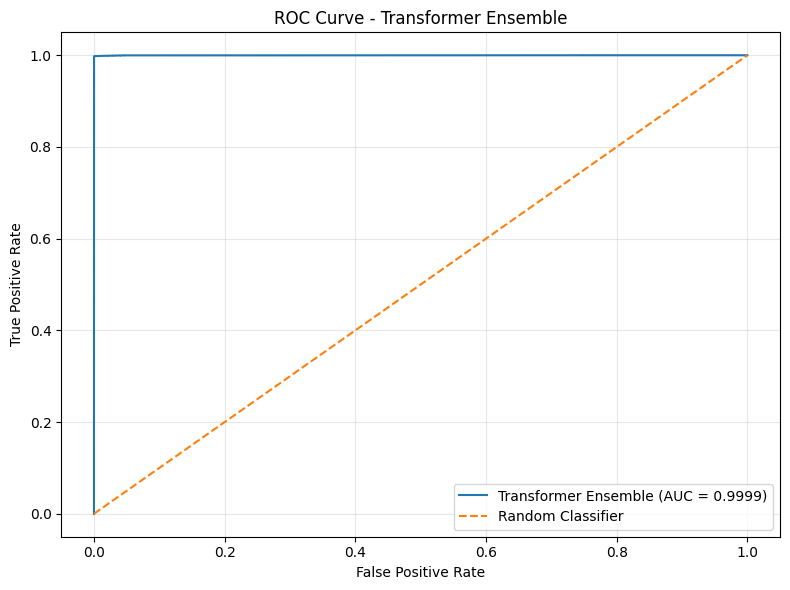

In [50]:
# ROC Curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Transformer Ensemble (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Transformer Ensemble")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

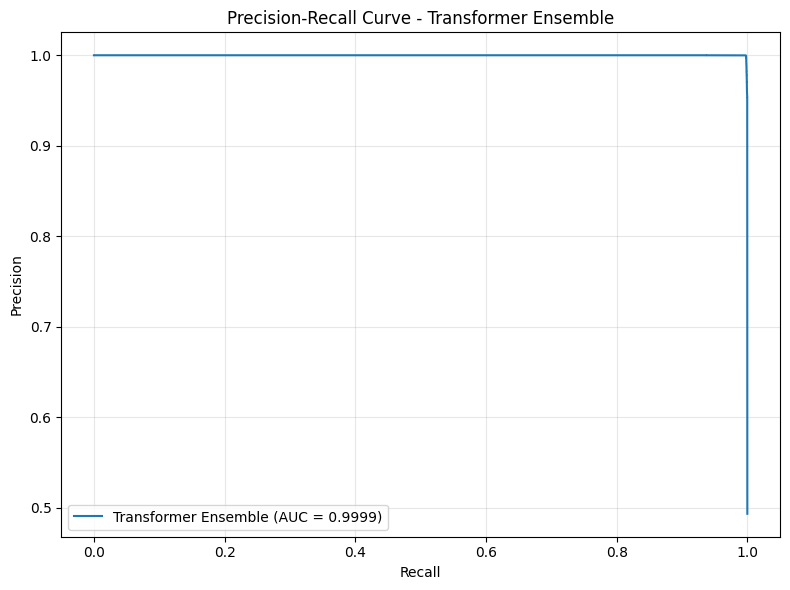

In [51]:
# Precision-Recall Curve

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Transformer Ensemble (AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Transformer Ensemble")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
# STEP 49: Save Final Transformer Models and Ensemble Configuration

import torch
import json

# Save model weights
torch.save(
    model_ft.state_dict(),
    "final_ft_transformer.pt"
)

torch.save(
    model_tab.state_dict(),
    "final_tab_transformer.pt"
)

torch.save(
    model_saint.state_dict(),
    "final_saint_transformer.pt"
)

# Save ensemble configuration
ensemble_config = {
    "FT-Transformer_weight": BEST_W_FT,
    "TabTransformer_weight": BEST_W_TAB,
    "SAINT_weight": BEST_W_SAINT,
    "num_features": NUM_FEATURES,
    "num_classes": NUM_CLASSES,
    "accuracy": float(final_accuracy),
    "precision": float(final_precision),
    "recall": float(final_recall),
    "weighted_f1": float(final_weighted_f1),
    "macro_f1": float(final_macro_f1)
}

with open("transformer_ensemble_config.json", "w") as f:
    json.dump(ensemble_config, f, indent=4)

print("=" * 60)
print("MODELS SAVED SUCCESSFULLY")
print("=" * 60)

print("1. final_ft_transformer.pt")
print("2. final_tab_transformer.pt")
print("3. final_saint_transformer.pt")
print("4. transformer_ensemble_config.json")

MODELS SAVED SUCCESSFULLY
1. final_ft_transformer.pt
2. final_tab_transformer.pt
3. final_saint_transformer.pt
4. transformer_ensemble_config.json


In [53]:
# Verify saved files

import os

saved_files = [
    "final_ft_transformer.pt",
    "final_tab_transformer.pt",
    "final_saint_transformer.pt",
    "transformer_ensemble_config.json"
]

print("\nSaved file verification:")

for file in saved_files:
    if os.path.exists(file):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"✓ {file}  ({size_mb:.2f} MB)")
    else:
        print(f"✗ {file} NOT FOUND")


Saved file verification:
✓ final_ft_transformer.pt  (3.37 MB)
✓ final_tab_transformer.pt  (3.34 MB)
✓ final_saint_transformer.pt  (3.37 MB)
✓ transformer_ensemble_config.json  (0.00 MB)


In [54]:
# STEP 50: Save preprocessing information

import joblib
import json
import os

# Save scaler
joblib.dump(
    scaler,
    "cse_cic_ids2018_scaler.pkl"
)

# Get feature names
feature_names = list(X.columns)

# Save feature names
with open("feature_names.json", "w") as f:
    json.dump(feature_names, f, indent=4)

# Save class information
class_info = {
    "num_features": int(NUM_FEATURES),
    "num_classes": int(NUM_CLASSES),
    "classes": [int(x) for x in np.unique(y_train)]
}

with open("class_info.json", "w") as f:
    json.dump(class_info, f, indent=4)

print("=" * 60)
print("PREPROCESSING FILES SAVED")
print("=" * 60)

print("✓ cse_cic_ids2018_scaler.pkl")
print("✓ feature_names.json")
print("✓ class_info.json")
print(f"\nNumber of features: {NUM_FEATURES}")
print(f"Number of classes : {NUM_CLASSES}")

PREPROCESSING FILES SAVED
✓ cse_cic_ids2018_scaler.pkl
✓ feature_names.json
✓ class_info.json

Number of features: 71
Number of classes : 2


In [55]:
# Verify all final project files

required_files = [
    "final_ft_transformer.pt",
    "final_tab_transformer.pt",
    "final_saint_transformer.pt",
    "transformer_ensemble_config.json",
    "cse_cic_ids2018_scaler.pkl",
    "feature_names.json",
    "class_info.json"
]

print("\nFINAL PROJECT FILE CHECK")
print("=" * 60)

all_found = True

for file in required_files:
    if os.path.exists(file):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"✓ {file} ({size_mb:.2f} MB)")
    else:
        print(f"✗ {file} NOT FOUND")
        all_found = False

print("=" * 60)

if all_found:
    print("✓ All required files are available.")
else:
    print("⚠ Some files are missing.")


FINAL PROJECT FILE CHECK
✓ final_ft_transformer.pt (3.37 MB)
✓ final_tab_transformer.pt (3.34 MB)
✓ final_saint_transformer.pt (3.37 MB)
✓ transformer_ensemble_config.json (0.00 MB)
✓ cse_cic_ids2018_scaler.pkl (0.00 MB)
✓ feature_names.json (0.00 MB)
✓ class_info.json (0.00 MB)
✓ All required files are available.


In [56]:
# STEP 51: Final Transformer Ensemble Prediction Function

def predict_network_traffic(X_new):
    """
    Predict new network traffic using the
    FT-Transformer + TabTransformer + SAINT ensemble.

    X_new:
        pandas DataFrame containing the same features
        used during model training.
    """

    # Make a copy so the original data is not modified
    X_input = X_new.copy()

    # Keep exactly the training feature order
    X_input = X_input[feature_names]

    # Convert values to numeric
    X_input = X_input.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Replace infinite values
    X_input = X_input.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Fill missing values using training medians
    X_input = X_input.fillna(
        X_train_median
    )

    # Apply the SAME scaler used during training
    X_scaled = scaler.transform(X_input)

    # Convert to PyTorch tensor
    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float32
    ).to(device)

    # Evaluation mode
    model_ft.eval()
    model_tab.eval()
    model_saint.eval()

    with torch.no_grad():

        # Individual model probabilities
        prob_ft = torch.softmax(
            model_ft(X_tensor),
            dim=1
        )

        prob_tab = torch.softmax(
            model_tab(X_tensor),
            dim=1
        )

        prob_saint = torch.softmax(
            model_saint(X_tensor),
            dim=1
        )

        # Weighted ensemble
        ensemble_prob = (
            BEST_W_FT * prob_ft +
            BEST_W_TAB * prob_tab +
            BEST_W_SAINT * prob_saint
        )

        # Final class
        predictions = torch.argmax(
            ensemble_prob,
            dim=1
        )

    # Move results to CPU
    predictions = predictions.cpu().numpy()
    ensemble_prob = ensemble_prob.cpu().numpy()

    # Create result DataFrame
    results = pd.DataFrame({
        "Predicted_Class": predictions,
        "Class_0_Probability": ensemble_prob[:, 0],
        "Class_1_Probability": ensemble_prob[:, 1]
    })

    return results

In [57]:
# Create training medians for missing-value handling

X_train_median = X_train.median()

print("Training median values saved.")
print("Number of features:", len(X_train_median))

Training median values saved.
Number of features: 71


In [58]:
# STEP 51 - FIXED Prediction Function

def predict_network_traffic(X_new):
    """
    Predict new network traffic using the
    FT-Transformer + TabTransformer + SAINT ensemble.
    """

    X_input = X_new.copy()

    # -------------------------------------------------
    # 1. Use the actual feature columns used for training
    # -------------------------------------------------
    if len(X_input.columns) != NUM_FEATURES:
        raise ValueError(
            f"Expected {NUM_FEATURES} features, "
            f"but received {len(X_input.columns)} features."
        )

    # -------------------------------------------------
    # 2. Convert to numeric
    # -------------------------------------------------
    X_input = X_input.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # -------------------------------------------------
    # 3. Replace infinite values
    # -------------------------------------------------
    X_input = X_input.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # -------------------------------------------------
    # 4. Fill missing values
    # -------------------------------------------------
    X_input = X_input.fillna(
        X_train.median()
    )

    # -------------------------------------------------
    # 5. Apply the SAME scaler
    # -------------------------------------------------
    X_scaled = scaler.transform(X_input)

    # -------------------------------------------------
    # 6. Convert to tensor
    # -------------------------------------------------
    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float32
    ).to(device)

    # -------------------------------------------------
    # 7. Evaluation mode
    # -------------------------------------------------
    model_ft.eval()
    model_tab.eval()
    model_saint.eval()

    with torch.no_grad():

        # FT-Transformer
        prob_ft = torch.softmax(
            model_ft(X_tensor),
            dim=1
        )

        # TabTransformer
        prob_tab = torch.softmax(
            model_tab(X_tensor),
            dim=1
        )

        # SAINT
        prob_saint = torch.softmax(
            model_saint(X_tensor),
            dim=1
        )

        # -------------------------------------------------
        # 8. Weighted ensemble
        # -------------------------------------------------
        ensemble_prob = (
            BEST_W_FT * prob_ft +
            BEST_W_TAB * prob_tab +
            BEST_W_SAINT * prob_saint
        )

        # Final prediction
        predictions = torch.argmax(
            ensemble_prob,
            dim=1
        )

    # -------------------------------------------------
    # 9. Convert to NumPy
    # -------------------------------------------------
    predictions = predictions.cpu().numpy()
    ensemble_prob = ensemble_prob.cpu().numpy()

    # -------------------------------------------------
    # 10. Create result
    # -------------------------------------------------
    results = pd.DataFrame({
        "Predicted_Class": predictions,
        "Class_0_Probability": ensemble_prob[:, 0],
        "Class_1_Probability": ensemble_prob[:, 1]
    })

    return results

In [59]:
# Test using existing test samples

sample_data = X_test.iloc[:5].copy()

prediction_results = predict_network_traffic(
    sample_data
)

display(prediction_results)

,Predicted_Class,Class_0_Probability,Class_1_Probability
0,1,0.000009,0.999991
1,0,0.999940,0.000060
2,0,0.999915,0.000085
3,1,0.000029,0.999970
4,0,0.999967,0.000033


In [60]:
# ============================================================
# RESEARCH PAPER TABLES
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# TABLE 1: Individual Models + Proposed Ensemble
# ------------------------------------------------------------

paper_table_1 = pd.DataFrame({
    "Model": [
        "FT-Transformer",
        "TabTransformer",
        "SAINT",
        "Proposed Ensemble"
    ],

    "Accuracy (%)": [
        test_results_ft["accuracy"] * 100,
        test_results_tab["accuracy"] * 100,
        test_results_saint["accuracy"] * 100,
        final_accuracy * 100
    ],

    "Precision (%)": [
        test_results_ft["precision"] * 100,
        test_results_tab["precision"] * 100,
        test_results_saint["precision"] * 100,
        final_precision * 100
    ],

    "Recall (%)": [
        test_results_ft["recall"] * 100,
        test_results_tab["recall"] * 100,
        test_results_saint["recall"] * 100,
        final_recall * 100
    ],

    "Weighted F1 (%)": [
        test_results_ft["weighted_f1"] * 100,
        test_results_tab["weighted_f1"] * 100,
        test_results_saint["weighted_f1"] * 100,
        final_weighted_f1 * 100
    ],

    "Macro F1 (%)": [
        test_results_ft["macro_f1"] * 100,
        test_results_tab["macro_f1"] * 100,
        test_results_saint["macro_f1"] * 100,
        final_macro_f1 * 100
    ]
})

print("TABLE 1: MODEL PERFORMANCE COMPARISON")

display(
    paper_table_1.style.format({
        "Accuracy (%)": "{:.4f}",
        "Precision (%)": "{:.4f}",
        "Recall (%)": "{:.4f}",
        "Weighted F1 (%)": "{:.4f}",
        "Macro F1 (%)": "{:.4f}"
    })
)

TABLE 1: MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),Weighted F1 (%),Macro F1 (%)
0,FT-Transformer,99.8785,99.8786,99.8785,99.8785,99.8784
1,TabTransformer,99.7986,99.7989,99.7986,99.7986,99.7986
2,SAINT,99.8439,99.8441,99.8439,99.8439,99.8439
3,Proposed Ensemble,99.8773,99.8775,99.8773,99.8773,99.8772


In [61]:
# ============================================================
# TABLE 2: ENSEMBLE WEIGHT OPTIMIZATION
# ============================================================

paper_table_2 = best_by_macro.head(10).copy()

paper_table_2.columns = [
    "FT Weight",
    "Tab Weight",
    "SAINT Weight",
    "Validation Accuracy",
    "Validation Macro F1",
    "Validation Weighted F1"
]

print("TABLE 2: TOP ENSEMBLE WEIGHT COMBINATIONS")

display(
    paper_table_2.style.format({
        "FT Weight": "{:.2f}",
        "Tab Weight": "{:.2f}",
        "SAINT Weight": "{:.2f}",
        "Validation Accuracy": "{:.4%}",
        "Validation Macro F1": "{:.6f}",
        "Validation Weighted F1": "{:.6f}"
    })
)

TABLE 2: TOP ENSEMBLE WEIGHT COMBINATIONS


,FT Weight,Tab Weight,SAINT Weight,Validation Accuracy,Validation Macro F1,Validation Weighted F1
0,0.90,0.05,0.05,99.8713%,0.998713,0.998713
1,0.70,0.10,0.20,99.8713%,0.998713,0.998713
2,0.95,0.00,0.05,99.8689%,0.998689,0.998689
3,0.90,0.00,0.10,99.8689%,0.998689,0.998689
4,0.85,0.00,0.15,99.8689%,0.998689,0.998689
5,0.75,0.00,0.25,99.8689%,0.998689,0.998689
6,0.80,0.05,0.15,99.8689%,0.998689,0.998689
7,0.80,0.00,0.20,99.8689%,0.998689,0.998689
8,0.70,0.05,0.25,99.8689%,0.998689,0.998689
9,0.75,0.05,0.20,99.8689%,0.998689,0.998689


In [62]:
# ============================================================
# TABLE 3: PER-CLASS PERFORMANCE
# ============================================================

report_dict = classification_report(
    y_test_true,
    final_test_pred,
    output_dict=True,
    zero_division=0
)

class_rows = []

for class_name in np.unique(y_test_true):

    class_key = str(class_name)

    class_rows.append({
        "Class": class_name,
        "Precision": report_dict[class_key]["precision"],
        "Recall": report_dict[class_key]["recall"],
        "F1-Score": report_dict[class_key]["f1-score"],
        "Support": int(report_dict[class_key]["support"])
    })

paper_table_3 = pd.DataFrame(class_rows)

print("TABLE 3: PER-CLASS PERFORMANCE")

display(
    paper_table_3.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Support": "{:d}"
    })
)

TABLE 3: PER-CLASS PERFORMANCE


,Class,Precision,Recall,F1-Score,Support
0,0,0.9978,0.9998,0.9988,42535
1,1,0.9998,0.9978,0.9988,41385


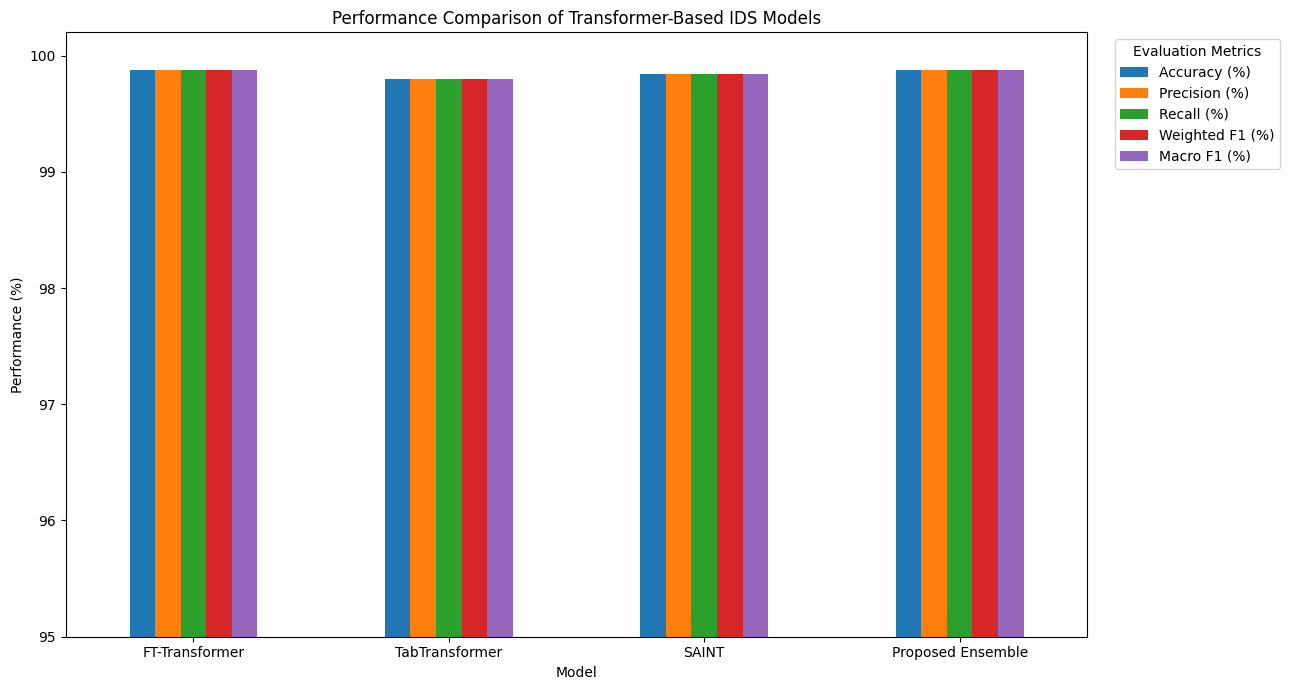

In [63]:
# ============================================================
# FIGURE: MODEL PERFORMANCE COMPARISON
# ============================================================

import matplotlib.pyplot as plt

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Weighted F1 (%)",
    "Macro F1 (%)"
]

plot_data = paper_table_1.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.xlabel("Model")
plt.ylabel("Performance (%)")
plt.title("Performance Comparison of Transformer-Based IDS Models")
plt.xticks(rotation=0)
plt.ylim(95, 100.2)
plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

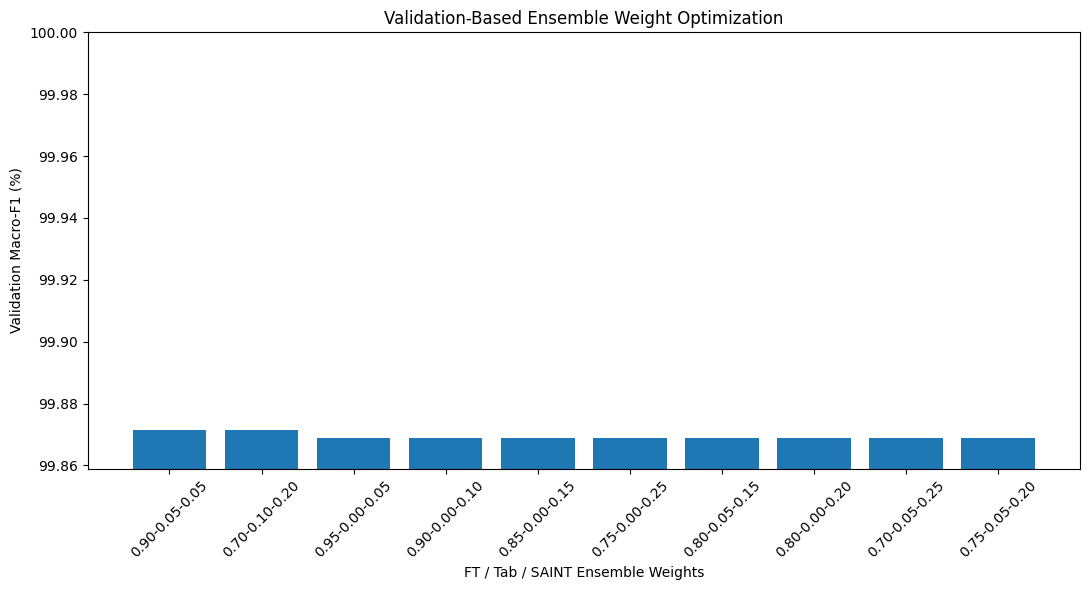

In [64]:
# ============================================================
# FIGURE: ENSEMBLE WEIGHT OPTIMIZATION
# ============================================================

top_weights = best_by_macro.head(10).copy()

labels = [
    f"{row['FT Weight']:.2f}-"
    f"{row['Tab Weight']:.2f}-"
    f"{row['SAINT Weight']:.2f}"
    for _, row in top_weights.iterrows()
]

scores = top_weights["Macro F1"].values * 100

plt.figure(figsize=(11, 6))

plt.bar(labels, scores)

plt.xlabel("FT / Tab / SAINT Ensemble Weights")
plt.ylabel("Validation Macro-F1 (%)")
plt.title("Validation-Based Ensemble Weight Optimization")

plt.xticks(rotation=45)

plt.ylim(
    min(scores) - 0.01,
    100.0
)

plt.tight_layout()
plt.show()

In [66]:
!pip -q install xgboost catboost

In [67]:

# ============================================================
# IDS MODEL COMPARISON: XGBOOST, CNN, LSTM, CATBOOST, RANDOM FOREST
# Dataset: CSE-CIC-IDS2018 | Binary classification
# ============================================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Convert labels to NumPy arrays
y_train_np = np.asarray(y_train).astype(int)
y_val_np   = np.asarray(y_val).astype(int)
y_test_np  = np.asarray(y_test).astype(int)

# Keep the same train, validation and test split
# Tree models use the preprocessed DataFrames
# CNN/LSTM use your notebook's scaled arrays

results = []
predictions = {}

def evaluate_model(name, y_true, y_pred, y_prob, elapsed):
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted_F1": f1_score(y_true, y_pred, average="weighted"),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Train_Time_sec": elapsed
    }
    results.append(row)
    predictions[name] = y_pred
    print(f"\n{name} classification report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))


# ------------------------------------------------------------
# 1. XGBOOST
# ------------------------------------------------------------
print("\nTraining XGBoost...")
model_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

start = time.time()
model_xgb.fit(X_train, y_train_np)
elapsed = time.time() - start

prob = model_xgb.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
evaluate_model("XGBoost", y_test_np, pred, prob, elapsed)


# ------------------------------------------------------------
# 2. CATBOOST
# ------------------------------------------------------------
print("\nTraining CatBoost...")
model_cat = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.1,
    loss_function="Logloss",
    verbose=False,
    random_seed=42,
    thread_count=-1
)

start = time.time()
model_cat.fit(X_train, y_train_np)
elapsed = time.time() - start

prob = model_cat.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
evaluate_model("CatBoost", y_test_np, pred, prob, elapsed)


# ------------------------------------------------------------
# 3. RANDOM FOREST
# ------------------------------------------------------------
print("\nTraining Random Forest...")
model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

start = time.time()
model_rf.fit(X_train, y_train_np)
elapsed = time.time() - start

prob = model_rf.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
evaluate_model("Random Forest", y_test_np, pred, prob, elapsed)


# ------------------------------------------------------------
# Prepare scaled arrays for CNN and LSTM
# ------------------------------------------------------------
Xtr = np.asarray(X_train_scaled, dtype=np.float32)
Xv  = np.asarray(X_val_scaled, dtype=np.float32)
Xte = np.asarray(X_test_scaled, dtype=np.float32)

# Conv1D/LSTM expect (samples, steps, features).
# Here each flow feature is treated as one step.
Xtr_seq = Xtr[..., np.newaxis]
Xv_seq  = Xv[..., np.newaxis]
Xte_seq = Xte[..., np.newaxis]


# ------------------------------------------------------------
# 4. CNN
# ------------------------------------------------------------
print("\nTraining CNN...")
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xtr_seq.shape[1], 1)),
    tf.keras.layers.Conv1D(64, kernel_size=3, padding="same",
                           activation="relu"),
    tf.keras.layers.MaxPooling1D(pool_size=2),
    tf.keras.layers.Conv1D(32, kernel_size=3, padding="same",
                           activation="relu"),
    tf.keras.layers.GlobalMaxPooling1D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start = time.time()
cnn.fit(
    Xtr_seq, y_train_np,
    validation_data=(Xv_seq, y_val_np),
    epochs=10,
    batch_size=1024,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)
elapsed = time.time() - start

prob = cnn.predict(Xte_seq, batch_size=1024, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)
evaluate_model("CNN", y_test_np, pred, prob, elapsed)


# ------------------------------------------------------------
# 5. LSTM
# ------------------------------------------------------------
print("\nTraining LSTM...")
lstm = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xtr_seq.shape[1], 1)),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

lstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start = time.time()
lstm.fit(
    Xtr_seq, y_train_np,
    validation_data=(Xv_seq, y_val_np),
    epochs=10,
    batch_size=1024,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)
elapsed = time.time() - start

prob = lstm.predict(Xte_seq, batch_size=1024, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)
evaluate_model("LSTM", y_test_np, pred, prob, elapsed)


# ------------------------------------------------------------
# FINAL COMPARISON TABLE
# ------------------------------------------------------------
comparison = pd.DataFrame(results)
comparison = comparison.sort_values("Macro_F1", ascending=False)

print("\n========== IDS MODEL COMPARISON ==========")
display(comparison.round(5))

comparison.to_csv("ids_baseline_comparison.csv", index=False)
print("Saved: ids_baseline_comparison.csv")



Training XGBoost...

XGBoost classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42535
           1       1.00      1.00      1.00     41385

    accuracy                           1.00     83920
   macro avg       1.00      1.00      1.00     83920
weighted avg       1.00      1.00      1.00     83920

Confusion matrix:
 [[42522    13]
 [   26 41359]]

Training CatBoost...

CatBoost classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42535
           1       1.00      1.00      1.00     41385

    accuracy                           1.00     83920
   macro avg       1.00      1.00      1.00     83920
weighted avg       1.00      1.00      1.00     83920

Confusion matrix:
 [[42526     9]
 [   30 41355]]

Training Random Forest...

Random Forest classification report:
              precision    recall  f1-score   support

           0      

,Model,Accuracy,Precision,Recall,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_sec
2,Random Forest,0.99957,0.99971,0.99942,0.99957,0.99957,0.99998,118.69073
0,XGBoost,0.99954,0.99969,0.99937,0.99954,0.99954,1.00000,35.55623
1,CatBoost,0.99954,0.99978,0.99928,0.99954,0.99954,1.00000,41.48536
3,CNN,0.99762,0.99828,0.99688,0.99762,0.99762,0.99974,34.61164
4,LSTM,0.98233,0.97675,0.98768,0.98233,0.98233,0.99579,35.50673


Saved: ids_baseline_comparison.csv


In [70]:
%whos

Variable                   Type                      Data/Info
--------------------------------------------------------------
BATCH_SIZE                 int                       1024
BEST_W_FT                  float                     0.55
BEST_W_SAINT               float                     0.4
BEST_W_TAB                 float                     0.05
CatBoostClassifier         type                      <class 'catboost.core.CatBoostClassifier'>
DATASET_PATH               str                       /content/drive/MyDrive/miniproject
DataLoader                 type                      <class 'torch.utils.data.dataloader.DataLoader'>
EPOCHS                     int                       30
EPOCHS_SAINT               int                       30
EPOCHS_TAB                 int                       30
F                          module                    <module 'torch.nn.functio<...>/torch/nn/functional.py'>
FILE_NAME                  str                       03-01-2018.csv
FILE_PATH   

In [74]:

# Add your existing ensemble to the comparison using TEST-set results

evaluate_model(
    "FT+Tab+SAINT Ensemble",
    y_test_np,
    np.asarray(final_test_pred).astype(int),
    np.asarray(final_test_prob).reshape(-1, 2)[:, 1],
    0.0
)

comparison = pd.DataFrame(results).sort_values(
    "Macro_F1", ascending=False
)

display(comparison.round(5))

comparison.to_csv("ids_all_models_comparison.csv", index=False)

print("Saved: ids_all_models_comparison.csv")



FT+Tab+SAINT Ensemble classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42535
           1       1.00      1.00      1.00     41385

    accuracy                           1.00     83920
   macro avg       1.00      1.00      1.00     83920
weighted avg       1.00      1.00      1.00     83920

Confusion matrix:
 [[42525    10]
 [   93 41292]]


,Model,Accuracy,Precision,Recall,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_sec
2,Random Forest,0.99957,0.99971,0.99942,0.99957,0.99957,0.99998,118.69073
0,XGBoost,0.99954,0.99969,0.99937,0.99954,0.99954,1.00000,35.55623
1,CatBoost,0.99954,0.99978,0.99928,0.99954,0.99954,1.00000,41.48536
6,FT+Tab+SAINT Ensemble,0.99877,0.99976,0.99775,0.99877,0.99877,0.99993,0.00000
5,FT+Tab+SAINT Ensemble,0.99877,0.99976,0.99775,0.99877,0.99877,0.99993,0.00000
3,CNN,0.99762,0.99828,0.99688,0.99762,0.99762,0.99974,34.61164
4,LSTM,0.98233,0.97675,0.98768,0.98233,0.98233,0.99579,35.50673


Saved: ids_all_models_comparison.csv


In [75]:

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    log_loss, brier_score_loss
)

# Use your existing test labels
y_true = np.asarray(y_test_np).astype(int).ravel()

# Get positive-class probabilities for each existing model
def get_probabilities(model, X, kind="sklearn"):
    start = time.perf_counter()

    if kind == "sklearn":
        p = model.predict_proba(X)[:, 1]
    else:
        p = model.predict(X, verbose=0).reshape(-1)

    elapsed = time.perf_counter() - start
    return np.asarray(p).ravel(), elapsed


model_probabilities = {}

# Tree-based models
model_probabilities["XGBoost"] = get_probabilities(
    model_xgb, X_test
)
model_probabilities["CatBoost"] = get_probabilities(
    model_cat, X_test
)
model_probabilities["Random Forest"] = get_probabilities(
    model_rf, X_test
)

# Neural network models: use the same sequence-shaped test data
model_probabilities["CNN"] = get_probabilities(
    cnn, Xte_seq, kind="keras"
)
model_probabilities["LSTM"] = get_probabilities(
    lstm, Xte_seq, kind="keras"
)

# Existing FT + Tab + SAINT ensemble
ensemble_probability = np.asarray(final_test_prob)

if ensemble_probability.ndim == 2:
    ensemble_probability = ensemble_probability[:, 1]
else:
    ensemble_probability = ensemble_probability.ravel()

model_probabilities["FT+Tab+SAINT Ensemble"] = (
    ensemble_probability, np.nan
)

# Calculate metrics from the confusion matrix and probabilities
def calculate_all_metrics(name, y_true, prob, inference_time):
    prob = np.asarray(prob).ravel()
    pred = (prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0
    far = fp / (fp + tn) if (fp + tn) else 0
    fnr = fn / (fn + tp) if (fn + tp) else 0
    npv = tn / (tn + fn) if (tn + fn) else 0
    fdr = fp / (fp + tp) if (fp + tp) else 0

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Error_Rate": 1 - accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall_Detection_Rate": recall_score(y_true, pred, zero_division=0),
        "Specificity": specificity,
        "F1_Attack": f1_score(y_true, pred, zero_division=0),
        "Macro_F1": f1_score(y_true, pred, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_true, pred, average="weighted", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, pred),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "PR_AUC_Average_Precision": average_precision_score(y_true, prob),
        "FAR": far,
        "FAR_percent": far * 100,
        "FPR": far,
        "FNR": fnr,
        "NPV": npv,
        "FDR": fdr,
        "MCC": matthews_corrcoef(y_true, pred),
        "Cohen_Kappa": cohen_kappa_score(y_true, pred),
        "Log_Loss": log_loss(
            y_true, np.clip(prob, 1e-7, 1 - 1e-7),
            labels=[0, 1]
        ),
        "Brier_Score": brier_score_loss(y_true, prob),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Inference_Time_sec": inference_time
    }


# Build a fresh table to avoid duplicate ensemble rows
metric_rows = []

for name, (prob, elapsed) in model_probabilities.items():
    metric_rows.append(
        calculate_all_metrics(name, y_true, prob, elapsed)
    )

all_metrics = pd.DataFrame(metric_rows).sort_values(
    "Macro_F1", ascending=False
).reset_index(drop=True)

display(all_metrics.round(6))

all_metrics.to_csv(
    "ids_all_performance_metrics.csv", index=False
)

print("Saved: ids_all_performance_metrics.csv")


,Model,Accuracy,Error_Rate,Precision,Recall_Detection_Rate,Specificity,F1_Attack,Macro_F1,Weighted_F1,Balanced_Accuracy,...,FDR,MCC,Cohen_Kappa,Log_Loss,Brier_Score,TN,FP,FN,TP,Inference_Time_sec
0,Random Forest,0.999571,0.000429,0.999710,0.999420,0.999718,0.999565,0.999571,0.999571,0.999569,...,0.000290,0.999142,0.999142,0.002259,0.000461,42523,12,24,41361,2.091083
1,XGBoost,0.999535,0.000465,0.999686,0.999372,0.999694,0.999529,0.999535,0.999535,0.999533,...,0.000314,0.999070,0.999070,0.001548,0.000374,42522,13,26,41359,1.111574
2,CatBoost,0.999535,0.000465,0.999782,0.999275,0.999788,0.999529,0.999535,0.999535,0.999532,...,0.000218,0.999070,0.999070,0.002173,0.000419,42526,9,30,41355,0.110128
3,FT+Tab+SAINT Ensemble,0.998773,0.001227,0.999758,0.997753,0.999765,0.998754,0.998772,0.998773,0.998759,...,0.000242,0.997547,0.997545,0.005544,0.001164,42525,10,93,41292,NaN
4,CNN,0.997617,0.002383,0.998282,0.996883,0.998331,0.997582,0.997616,0.997617,0.997607,...,0.001718,0.995234,0.995233,0.009265,0.001859,42464,71,129,41256,7.875057
5,LSTM,0.982328,0.017672,0.976749,0.987677,0.977125,0.982183,0.982327,0.982329,0.982401,...,0.023251,0.964714,0.964656,0.063934,0.014909,41562,973,510,40875,7.827474


Saved: ids_all_performance_metrics.csv


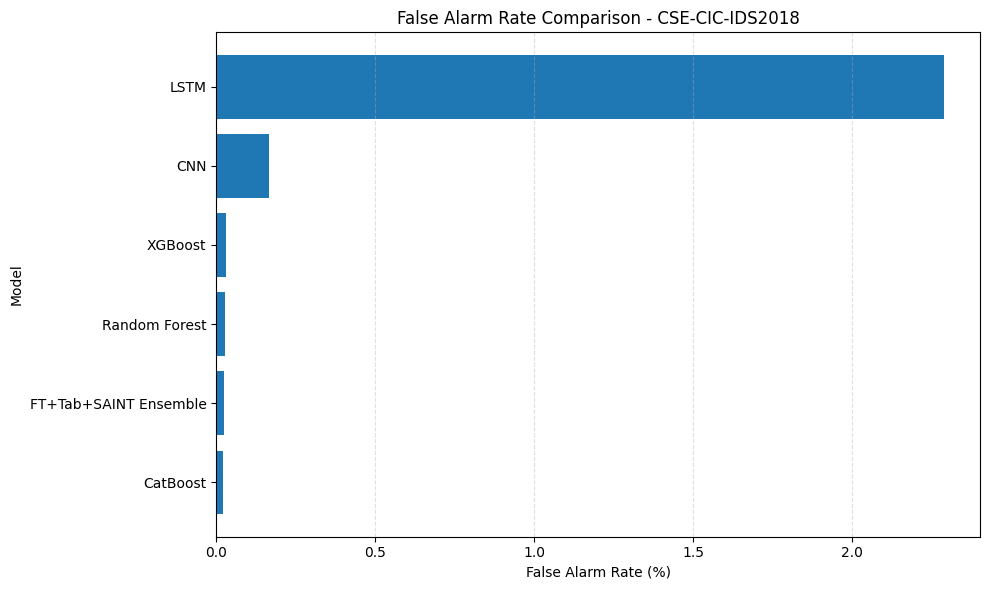

Saved: ids_false_alarm_rate_comparison.png


In [76]:

far_plot = all_metrics.sort_values("FAR_percent", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(far_plot["Model"], far_plot["FAR_percent"])
plt.xlabel("False Alarm Rate (%)")
plt.ylabel("Model")
plt.title("False Alarm Rate Comparison - CSE-CIC-IDS2018")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("ids_false_alarm_rate_comparison.png", dpi=300)
plt.show()

print("Saved: ids_false_alarm_rate_comparison.png")


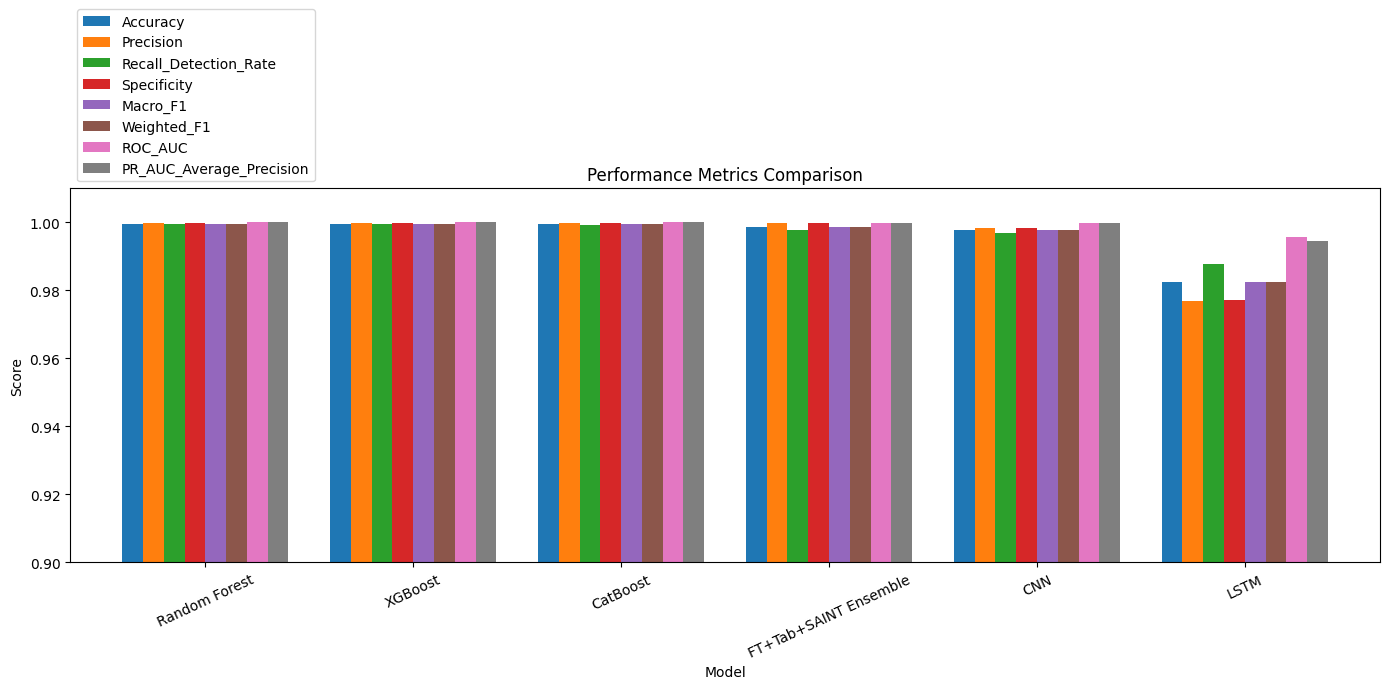

In [77]:

main_metrics = [
    "Accuracy", "Precision", "Recall_Detection_Rate",
    "Specificity", "Macro_F1", "Weighted_F1",
    "ROC_AUC", "PR_AUC_Average_Precision"
]

plot_df = all_metrics.set_index("Model")[main_metrics]

ax = plot_df.plot(
    kind="bar", figsize=(14, 7), width=0.8
)
ax.set_ylabel("Score")
ax.set_title("Performance Metrics Comparison")
ax.set_ylim(0.90, 1.01)
ax.tick_params(axis="x", rotation=25)
plt.legend(loc="lower left", bbox_to_anchor=(0, 1))
plt.tight_layout()
plt.savefig("ids_all_metrics_comparison.png", dpi=300)
plt.show()


In [78]:

print("DataFrame columns:")
print(df.columns.tolist())

print("\nAvailable attack labels:")
for col in df.columns:
    if any(word in col.lower() for word in ["label", "attack", "class"]):
        print(f"\nColumn: {col}")
        print(df[col].value_counts(dropna=False).head(20))


DataFrame columns:
['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk

In [80]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Use the 71 features already selected by your existing pipeline
feature_cols = X_train.columns.tolist()

# Align original attack labels with X using their row indexes
attack_labels = df.loc[X.index, "Label"].astype(str).str.strip()
features = X.loc[:, feature_cols].copy()

# Remove any repeated CSV header rows
valid_rows = (
    attack_labels.ne("Label")
    & attack_labels.notna()
    & df.loc[X.index, "Target"].notna()
)

features = features.loc[valid_rows].copy()
attack_labels = attack_labels.loc[valid_rows]
binary_labels = pd.to_numeric(
    df.loc[features.index, "Target"]
).astype(int)

# Choose the attack type to exclude from training
HELD_OUT_ATTACK = "SQL Injection"

if HELD_OUT_ATTACK not in set(attack_labels):
    raise ValueError(
        f"{HELD_OUT_ATTACK} not found. Check spelling and spaces."
    )

# All samples of the held-out attack must stay out of training
unseen_mask = attack_labels.eq(HELD_OUT_ATTACK)
benign_mask = attack_labels.eq("Benign")
known_attack_mask = ~(unseen_mask | benign_mask)

# Training: benign + all other attack types
train_idx = features.index[benign_mask | known_attack_mask]

# Testing: held-out attack + a separate sample of benign traffic
benign_idx = features.index[benign_mask]

benign_train_idx, benign_test_idx = train_test_split(
    benign_idx,
    test_size=0.20,
    random_state=42
)

test_idx = features.index[unseen_mask].union(
    benign_test_idx
)

X_unseen_train = features.loc[train_idx]
y_unseen_train = binary_labels.loc[train_idx]

X_unseen_test = features.loc[test_idx]
y_unseen_test = binary_labels.loc[test_idx]

# Report the split
print("Held-out attack:", HELD_OUT_ATTACK)
print("Training samples:", len(X_unseen_train))
print("Test samples:", len(X_unseen_test))
print("\nTraining class counts:")
print(y_unseen_train.value_counts())
print("\nTest class counts:")
print(y_unseen_test.value_counts())
print("\nAttack types in training:")
print(sorted(attack_labels.loc[train_idx].unique()))
print("\nHeld-out attack samples in training:",
      int(attack_labels.loc[train_idx].eq(HELD_OUT_ATTACK).sum()))
print("Held-out attack samples in test:",
      int(attack_labels.loc[test_idx].eq(HELD_OUT_ATTACK).sum()))


Held-out attack: SQL Injection
Training samples: 419509
Test samples: 42622

Training class counts:
Target
0    212671
1    206838
Name: count, dtype: int64

Test class counts:
Target
0    42535
1       87
Name: count, dtype: int64

Attack types in training:
['Benign', 'Bot', 'Brute Force -Web', 'Brute Force -XSS', 'DDOS attack-HOIC', 'DDOS attack-LOIC-UDP', 'DDoS attacks-LOIC-HTTP', 'DoS attacks-GoldenEye', 'DoS attacks-SlowHTTPTest', 'DoS attacks-Slowloris', 'FTP-BruteForce']

Held-out attack samples in training: 0
Held-out attack samples in test: 87


In [81]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

# Convert features to numeric and replace infinities
Xtr_unseen_raw = X_unseen_train.replace([np.inf, -np.inf], np.nan)
Xte_unseen_raw = X_unseen_test.replace([np.inf, -np.inf], np.nan)

# Remove columns that are entirely missing in training
usable_cols = Xtr_unseen_raw.columns[
    Xtr_unseen_raw.notna().any(axis=0)
].tolist()

Xtr_unseen_raw = Xtr_unseen_raw[usable_cols]
Xte_unseen_raw = Xte_unseen_raw[usable_cols]

# Fit imputer on training data only
unseen_imputer = SimpleImputer(strategy="median")

Xtr_unseen = unseen_imputer.fit_transform(Xtr_unseen_raw)
Xte_unseen = unseen_imputer.transform(Xte_unseen_raw)

# Remove any remaining constant columns based on training data
nonconstant = np.std(Xtr_unseen, axis=0) > 0

Xtr_unseen = Xtr_unseen[:, nonconstant]
Xte_unseen = Xte_unseen[:, nonconstant]

# Fit scaler on training data only
unseen_scaler = StandardScaler()

Xtr_unseen = unseen_scaler.fit_transform(Xtr_unseen).astype("float32")
Xte_unseen = unseen_scaler.transform(Xte_unseen).astype("float32")

ytr_unseen = y_unseen_train.to_numpy().astype("int64")
yte_unseen = y_unseen_test.to_numpy().astype("int64")

print("Training shape:", Xtr_unseen.shape)
print("Test shape:", Xte_unseen.shape)
print("Training labels:", np.unique(ytr_unseen, return_counts=True))
print("Test labels:", np.unique(yte_unseen, return_counts=True))


Training shape: (419509, 71)
Test shape: (42622, 71)
Training labels: (array([0, 1]), array([212671, 206838]))
Test labels: (array([0, 1]), array([42535,    87]))


In [82]:

import inspect

print("FTTransformer:")
print(inspect.signature(FTTransformer))

print("\nTabTransformer:")
print(inspect.signature(TabTransformer))

print("\nSAINTTransformer:")
print(inspect.signature(SAINTTransformer))


FTTransformer:
(num_features, num_classes, embed_dim=128, num_heads=8, num_layers=4, dropout=0.2)

TabTransformer:
(num_features, num_classes, embed_dim=128, num_heads=8, num_layers=4, dropout=0.2)

SAINTTransformer:
(num_features, num_classes, embed_dim=128, num_heads=8, num_layers=4, dropout=0.2)


In [83]:

print("FT model:")
print(model_ft)

print("\nTab model:")
print(model_tab)

print("\nSAINT model:")
print(model_saint)

print("\nDevice:", device)


FT model:
FTTransformer(
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_fe

In [85]:

import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)

# Keep the unseen test set untouched during training
X_fit, X_val_unseen, y_fit, y_val_unseen = train_test_split(
    Xtr_unseen,
    ytr_unseen,
    test_size=0.10,
    random_state=42,
    stratify=ytr_unseen
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH = 512
MAX_EPOCHS = 10
PATIENCE = 3

train_ds = TensorDataset(
    torch.tensor(X_fit, dtype=torch.float32),
    torch.tensor(y_fit, dtype=torch.long)
)
val_ds = TensorDataset(
    torch.tensor(X_val_unseen, dtype=torch.float32),
    torch.tensor(y_val_unseen, dtype=torch.long)
)

train_loader_unseen = DataLoader(
    train_ds, batch_size=BATCH, shuffle=True
)
val_loader_unseen = DataLoader(
    val_ds, batch_size=BATCH, shuffle=False
)

def fresh_model(existing_model):
    # Copy architecture, then initialize fresh weights
    model = copy.deepcopy(existing_model)
    for module in model.modules():
        if hasattr(module, "reset_parameters"):
            module.reset_parameters()
    return model.to(device)

def train_unseen_model(existing_model, model_name):
    model = fresh_model(existing_model)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-4, weight_decay=1e-4
    )
    criterion = nn.CrossEntropyLoss()

    best_f1 = -1
    best_state = None
    patience_count = 0
    start_time = time.perf_counter()

    for epoch in range(MAX_EPOCHS):
        model.train()
        total_loss = 0.0

        for xb, yb in train_loader_unseen:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # Validate only on data drawn from known training classes
        model.eval()
        val_true, val_pred = [], []

        with torch.no_grad():
            for xb, yb in val_loader_unseen:
                logits = model(xb.to(device))
                pred = logits.argmax(dim=1).cpu().numpy()
                val_pred.extend(pred)
                val_true.extend(yb.numpy())

        val_f1 = f1_score(
            val_true, val_pred, average="macro", zero_division=0
        )
        avg_loss = total_loss / len(train_loader_unseen)

        print(
            f"{model_name} | Epoch {epoch+1}/{MAX_EPOCHS} "
            f"| Loss={avg_loss:.5f} | Val Macro-F1={val_f1:.5f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= PATIENCE:
                print("Early stopping.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    elapsed = time.perf_counter() - start_time
    return model, elapsed

# Train fresh versions of the existing architectures
model_ft_unseen, time_ft_unseen = train_unseen_model(
    model_ft, "FT-Transformer"
)
model_tab_unseen, time_tab_unseen = train_unseen_model(
    model_tab, "TabTransformer"
)
model_saint_unseen, time_saint_unseen = train_unseen_model(
    model_saint, "SAINT"
)

print("\nAll three models trained for the unseen-attack experiment.")


FT-Transformer | Epoch 1/10 | Loss=0.03388 | Val Macro-F1=0.99797
FT-Transformer | Epoch 2/10 | Loss=0.00846 | Val Macro-F1=0.99833
FT-Transformer | Epoch 3/10 | Loss=0.00791 | Val Macro-F1=0.99864
FT-Transformer | Epoch 4/10 | Loss=0.00700 | Val Macro-F1=0.99852
FT-Transformer | Epoch 5/10 | Loss=0.00695 | Val Macro-F1=0.99874
FT-Transformer | Epoch 6/10 | Loss=0.00686 | Val Macro-F1=0.99890
FT-Transformer | Epoch 7/10 | Loss=0.00664 | Val Macro-F1=0.99900
FT-Transformer | Epoch 8/10 | Loss=0.00725 | Val Macro-F1=0.99828
FT-Transformer | Epoch 9/10 | Loss=0.00604 | Val Macro-F1=0.99878
FT-Transformer | Epoch 10/10 | Loss=0.00719 | Val Macro-F1=0.99833
Early stopping.
TabTransformer | Epoch 1/10 | Loss=0.20778 | Val Macro-F1=0.98229
TabTransformer | Epoch 2/10 | Loss=0.04625 | Val Macro-F1=0.93827
TabTransformer | Epoch 3/10 | Loss=0.02513 | Val Macro-F1=0.99368
TabTransformer | Epoch 4/10 | Loss=0.02011 | Val Macro-F1=0.94305
TabTransformer | Epoch 5/10 | Loss=0.01687 | Val Macro-F1=0

In [86]:

X_test_tensor_unseen = torch.tensor(
    Xte_unseen, dtype=torch.float32
)

def get_torch_probabilities(model, X_tensor, batch_size=512):
    model.eval()
    chunks = []

    with torch.no_grad():
        for start in range(0, len(X_tensor), batch_size):
            xb = X_tensor[start:start + batch_size].to(device)
            probabilities = torch.softmax(model(xb), dim=1)
            chunks.append(probabilities.cpu().numpy())

    return np.concatenate(chunks, axis=0)

p_ft = get_torch_probabilities(
    model_ft_unseen, X_test_tensor_unseen
)
p_tab = get_torch_probabilities(
    model_tab_unseen, X_test_tensor_unseen
)
p_saint = get_torch_probabilities(
    model_saint_unseen, X_test_tensor_unseen
)

# Equal weights chosen before examining held-out attack results
ensemble_unseen_prob = (
    p_ft + p_tab + p_saint
) / 3.0

y_test_unseen = yte_unseen
ensemble_unseen_pred = np.argmax(ensemble_unseen_prob, axis=1)

tn, fp, fn, tp = confusion_matrix(
    y_test_unseen, ensemble_unseen_pred, labels=[0, 1]
).ravel()

sql_mask = (
    attack_labels.loc[test_idx].to_numpy() == "SQL Injection"
)
sql_true = y_test_unseen[sql_mask]
sql_pred = ensemble_unseen_pred[sql_mask]

print("=== UNSEEN SQL INJECTION RESULTS ===")
print("Overall test accuracy:",
      round(accuracy_score(y_test_unseen, ensemble_unseen_pred), 6))
print("Overall Macro-F1:",
      round(f1_score(
          y_test_unseen, ensemble_unseen_pred,
          average="macro", zero_division=0
      ), 6))
print("Unseen SQL Injection samples:", int(sql_mask.sum()))
print("SQL Injection detected:",
      int((sql_pred == 1).sum()))
print("SQL Injection missed:",
      int((sql_pred == 0).sum()))
print("Unseen-attack detection rate:",
      round((sql_pred == 1).mean() * 100, 4), "%")
print("Unseen-attack false-negative rate:",
      round((sql_pred == 0).mean() * 100, 4), "%")
print("Benign false-alarm rate:",
      round(fp / (fp + tn) * 100, 6), "%")
print("Overall ROC-AUC:",
      round(roc_auc_score(
          y_test_unseen, ensemble_unseen_prob[:, 1]
      ), 6))

unseen_result = pd.DataFrame([{
    "Held_Out_Attack": "SQL Injection",
    "Test_Samples": len(y_test_unseen),
    "Unseen_Attack_Samples": int(sql_mask.sum()),
    "Detected_Unseen_Attacks": int((sql_pred == 1).sum()),
    "Missed_Unseen_Attacks": int((sql_pred == 0).sum()),
    "Unseen_Attack_Recall": recall_score(
        sql_true, sql_pred, zero_division=0
    ),
    "Unseen_Attack_FNR": (
        float((sql_pred == 0).mean()) if len(sql_pred) else np.nan
    ),
    "Benign_FAR": fp / (fp + tn) if (fp + tn) else np.nan,
    "Overall_Accuracy": accuracy_score(
        y_test_unseen, ensemble_unseen_pred
    ),
    "Overall_Macro_F1": f1_score(
        y_test_unseen, ensemble_unseen_pred,
        average="macro", zero_division=0
    )
}])

display(unseen_result.round(6))
unseen_result.to_csv("sql_injection_unseen_attack_results.csv", index=False)
print("Saved: sql_injection_unseen_attack_results.csv")


=== UNSEEN SQL INJECTION RESULTS ===
Overall test accuracy: 0.997396
Overall Macro-F1: 0.575684
Unseen SQL Injection samples: 87
SQL Injection detected: 10
SQL Injection missed: 77
Unseen-attack detection rate: 11.4943 %
Unseen-attack false-negative rate: 88.5057 %
Benign false-alarm rate: 0.079934 %
Overall ROC-AUC: 0.932014


,Held_Out_Attack,Test_Samples,Unseen_Attack_Samples,Detected_Unseen_Attacks,Missed_Unseen_Attacks,Unseen_Attack_Recall,Unseen_Attack_FNR,Benign_FAR,Overall_Accuracy,Overall_Macro_F1
0,SQL Injection,42622,87,10,77,0.114943,0.885057,0.000799,0.997396,0.575684


Saved: sql_injection_unseen_attack_results.csv


SQL Injection probability percentiles:
count    87.000000
mean      0.158313
std       0.275775
min       0.000348
25%       0.002282
50%       0.007998
75%       0.212493
90%       0.536830
95%       0.891994
max       0.974443
dtype: float64

Benign probability percentiles:
count    42535.000000
mean         0.004717
std          0.032070
min          0.000025
50%          0.000122
90%          0.004655
95%          0.017891
99%          0.049818
max          0.992702
dtype: float64


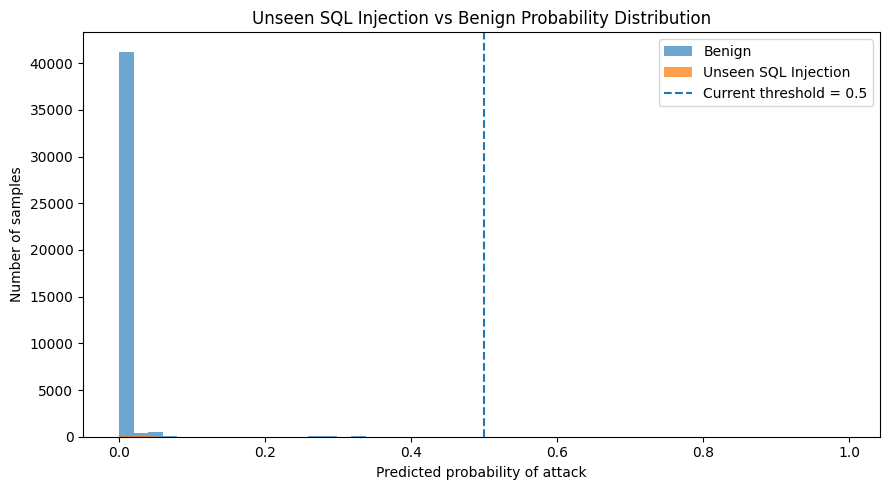

In [87]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Existing probabilities from the unseen-attack experiment
prob_attack = ensemble_unseen_prob[:, 1]

sql_mask = (
    attack_labels.loc[test_idx].to_numpy() == "SQL Injection"
)
benign_test_mask = (
    attack_labels.loc[test_idx].to_numpy() == "Benign"
)

sql_probs = prob_attack[sql_mask]
benign_probs = prob_attack[benign_test_mask]

print("SQL Injection probability percentiles:")
print(pd.Series(sql_probs).describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

print("\nBenign probability percentiles:")
print(pd.Series(benign_probs).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
))

plt.figure(figsize=(9, 5))
plt.hist(benign_probs, bins=50, alpha=0.65, label="Benign")
plt.hist(sql_probs, bins=20, alpha=0.75, label="Unseen SQL Injection")
plt.axvline(0.5, linestyle="--", label="Current threshold = 0.5")
plt.xlabel("Predicted probability of attack")
plt.ylabel("Number of samples")
plt.title("Unseen SQL Injection vs Benign Probability Distribution")
plt.legend()
plt.tight_layout()
plt.savefig("unseen_sql_probability_distribution.png", dpi=300)
plt.show()


In [88]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

prob_attack = ensemble_unseen_prob[:, 1]

sql_mask = (
    attack_labels.loc[test_idx].to_numpy() == "SQL Injection"
)
benign_mask = (
    attack_labels.loc[test_idx].to_numpy() == "Benign"
)

y_true = y_test_unseen

results = []

for threshold in [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    pred = (prob_attack >= threshold).astype(int)

    sql_recall = np.mean(pred[sql_mask] == 1)
    benign_far = np.mean(pred[benign_mask] == 1)

    results.append({
        "Threshold": threshold,
        "SQL detected": int(pred[sql_mask].sum()),
        "SQL total": int(sql_mask.sum()),
        "SQL recall (%)": round(sql_recall * 100, 2),
        "Benign false alarms": int(pred[benign_mask].sum()),
        "Benign FAR (%)": round(benign_far * 100, 3)
    })

threshold_results = pd.DataFrame(results)
display(threshold_results)

,Threshold,SQL detected,SQL total,SQL recall (%),Benign false alarms,Benign FAR (%)
0,0.01,43,87,49.43,3440,8.087
1,0.02,39,87,44.83,1280,3.009
2,0.05,28,87,32.18,401,0.943
3,0.10,25,87,28.74,348,0.818
4,0.20,23,87,26.44,305,0.717
5,0.30,19,87,21.84,142,0.334
6,0.40,14,87,16.09,45,0.106
7,0.50,10,87,11.49,34,0.080


In [90]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Same unseen SQL Injection test set for every model
y_true = y_test_unseen

attack_labels_test = attack_labels.loc[test_idx].to_numpy()
sql_mask = attack_labels_test == "SQL Injection"
benign_mask = attack_labels_test == "Benign"

# Store probabilities from the deep-learning models
model_probs = {
    "FT-Transformer": p_ft[:, 1],
    "TabTransformer": p_tab[:, 1],
    "SAINT": p_saint[:, 1],
    "Hybrid Ensemble": ensemble_unseen_prob[:, 1]
}

# Train traditional ML baselines on the same training data
baselines = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )

}

for name, model in baselines.items():
    model.fit(Xtr_unseen, ytr_unseen)

    # Find the probability column for attack class 1
    attack_col = list(model.classes_).index(1)
    model_probs[name] = model.predict_proba(Xte_unseen)[:, attack_col]

# Evaluate every model at the same threshold
rows = []

for name, probs in model_probs.items():
    pred = (probs >= 0.5).astype(int)

    rows.append({
        "Model": name,
        "Accuracy (%)": round(100 * accuracy_score(y_true, pred), 3),
        "Macro-F1 (%)": round(
            100 * f1_score(y_true, pred, average="macro", zero_division=0), 3
        ),
        "Unseen SQL detected": int(pred[sql_mask].sum()),
        "SQL recall (%)": round(100 * pred[sql_mask].mean(), 2),
        "SQL missed": int((pred[sql_mask] == 0).sum()),
        "Benign false alarms": int(pred[benign_mask].sum()),
        "Benign FAR (%)": round(100 * pred[benign_mask].mean(), 3),
        "ROC-AUC": round(roc_auc_score(y_true, probs), 4)
    })

comparison_df = pd.DataFrame(rows).sort_values(
    "SQL recall (%)", ascending=False
)

display(comparison_df)

comparison_df.to_csv(
    "unseen_sql_model_comparison.csv", index=False
)

print("Saved: unseen_sql_model_comparison.csv")

,Model,Accuracy (%),Macro-F1 (%),Unseen SQL detected,SQL recall (%),SQL missed,Benign false alarms,Benign FAR (%),ROC-AUC
5,Random Forest,99.887,80.924,39,44.83,48,0,0.000,0.9998
0,FT-Transformer,99.812,65.470,18,20.69,69,11,0.026,0.9612
4,Logistic Regression,95.786,49.906,18,20.69,69,1727,4.060,0.5238
2,SAINT,99.716,58.772,13,14.94,74,47,0.110,0.7280
3,Hybrid Ensemble,99.740,57.568,10,11.49,77,34,0.080,0.9320
1,TabTransformer,99.125,52.082,9,10.34,78,295,0.694,0.8527


Saved: unseen_sql_model_comparison.csv


In [2]:
import numpy as np
from sklearn.impute import SimpleImputer

X = X.replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

X = pd.DataFrame(X_imputed, columns=X.columns, index=X.index)

print("Missing values after handling:", X.isnull().sum().sum())

NameError: name 'X' is not defined